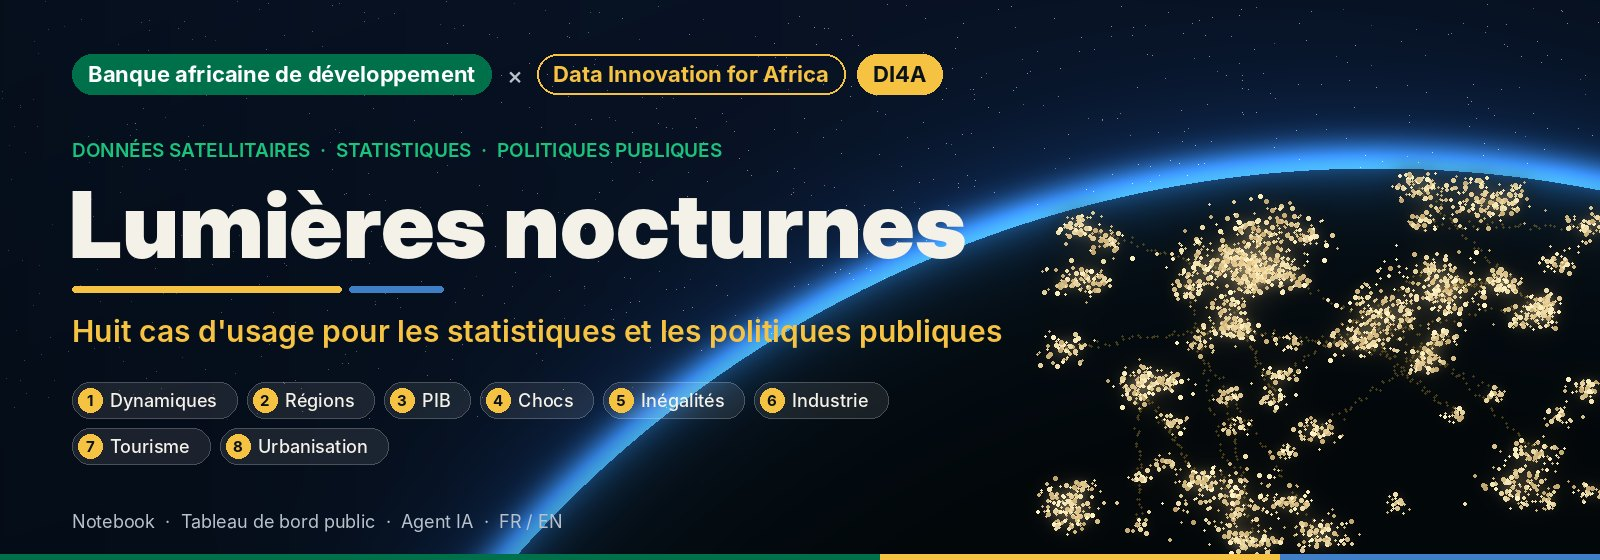

# 🛰️ Lumières nocturnes : huit cas d'usage pour les statistiques et les politiques publiques

**Banque africaine de développement** &nbsp;×&nbsp; **Data Innovation for Africa (DI4A)**

> ©️ **© 2026 AfDB-DI4A — mention de la source obligatoire.** Toute reproduction ou réutilisation de ce notebook, de
> ses résultats ou du tableau de bord qui en est issu doit indiquer la source : **« Source : AfDB-DI4A »**
> (conditions complètes en fin de notebook).

> **Huit cas d'usage professionnels · tableau de bord public · assistant IA**
>
> Un pipeline reproductible, paramétré par un code ISO3, qui exploite les lumières nocturnes observées par satellite,
> croisées avec des données complémentaires (population, bâti, pollution, température de surface, comptes nationaux),
> pour répondre à **huit questions de statistique et de politique publique** : dynamiques économiques, croissance
> régionale, relation avec le PIB, chocs et résilience, inégalités et électrification, zones industrielles, tourisme
> saisonnier, urbanisation. Les résultats sont publiés sur un tableau de bord web public et un agent IA répond uniquement à partir
> de ces résultats.

Compatible **Google Colab**, **Kaggle** et **Jupyter local** ·
requiert un projet **Google Earth Engine** (ou `SYNTHETIC_TEST = True` pour un essai sans Earth Engine).

| | |
|---|---|
| **Entrée** | un code pays ISO3 (ex. `TUN`, `SEN`, `KEN`) et une période |
| **Données** | VIIRS (mensuel, annuel), DMSP-OLS, Black Marble quotidien, GHSL (population, bâti non résidentiel), WorldPop, Sentinel-5P (NO₂, SO₂), MODIS (température de surface), OpenStreetMap, Banque mondiale (PIB, valeur ajoutée industrielle, accès à l'électricité) |
| **Sorties** | 8 cas d'usage : dynamiques, croissance régionale, NTL–PIB, chocs, inégalités et électrification, zones industrielles, tourisme saisonnier, urbanisation |
| **Livrables** | un tableau de bord bilingue (FR/EN) publié sur GitHub Pages en un seul appel, et un assistant IA (Groq, Gemini ou Ollama) dans le notebook et sur le site |

> ℹ️ **Comment lire ce notebook** — Le sommaire (icône ☰ à gauche dans Colab) liste les 19 sections ; chacune peut
> être repliée. Chaque section s'ouvre sur un encadré : 🎯 objectif, 📚 notions clés, 🛠️ méthode, 🔎 que faut-il
> retenir. Les interprétations en fin de section sont **générées à partir des résultats** du pays étudié, avec un niveau
> de confiance. Le texte est en français, le code en anglais. Une version anglaise de ce notebook existe
> (`NTL_8_use_cases_EN.ipynb`).

---

<sub>**SECTION 00 / 18**</sub>

## 📋 0. Résumé exécutif

*Messages clés générés automatiquement, chacun avec son niveau de confiance*

> Les messages clés ci-dessous (un ou deux par cas d'usage) sont **générés automatiquement** à la fin de l'exécution
> (section 13) à partir des résultats. Chaque message porte un niveau de confiance — 🟢 élevée, 🟠 moyenne, 🔴 faible —
> et son motif. Lors de la première exécution, la cellule affiche un espace réservé, rempli dès que la section 13 a tourné.

In [ ]:
from IPython.display import display, Markdown
EXEC_SUMMARY = display(Markdown("*Le résumé exécutif s'affichera ici après l'exécution de la section 13.*"),
                       display_id="exec-summary")

---

<sub>**SECTION 01 / 18**</sub>

## 💡 1. Introduction : ce que les lumières nocturnes permettent de mesurer — huit cas d'usage

*Ce que mesurent les lumières — et ce qu'elles ne disent pas*

> 🎯 **Objectif** — Comprendre ce que mesurent les lumières nocturnes (NTL), pourquoi elles renseignent sur l'activité
> économique, et où s'arrête ce qu'elles peuvent dire.

**L'intuition.** Produire, transporter, commercer et consommer exige de l'énergie, et une partie de cette énergie
s'échappe la nuit sous forme de lumière visible depuis l'espace. Plus une zone est active, plus elle brille. Les
capteurs satellitaires mesurent cette lumière partout, chaque nuit, avec la même méthode : c'est un indicateur
**homogène, spatialement fin et rapide**, là où les comptes nationaux sont annuels, tardifs et rarement régionaux.

**Ce que dit la littérature.**
- *Henderson, Storeygard & Weil (2012, AER)* — la croissance des lumières suit celle du PIB ; l'élasticité du PIB aux
  lumières est d'environ 0,3 ; les lumières améliorent les estimations de croissance là où les statistiques sont faibles.
- *Chen & Nordhaus (2011, PNAS)* — les lumières ajoutent de l'information surtout pour les pays à statistiques fragiles
  et pour les régions infranationales.
- *Elvidge et al. (2017, 2021)* — produits VIIRS mensuels et annuels (VNL V2) : correction de la lumière parasite,
  masques de fond et de lumières éphémères.
- *Román et al. (2018)* — NASA Black Marble : correction BRDF et lunaire, adapté aux séries quotidiennes.
- *Li et al. (2020, Scientific Data)* — série harmonisée DMSP–VIIRS 1992–2021.
- *Gibson, Olivia & Boe-Gibson (2020-2021)* — limites des lumières dans les zones rurales et peu denses.

**Ce qu'elles ne disent pas.** Les lumières mesurent un *rayonnement* vers 01 h 30, pas une valeur ajoutée.
L'agriculture, le commerce de jour, une grande partie des services et l'économie informelle rurale sont peu visibles.
La section 13 et la page « Méthode & limites » du tableau de bord détaillent ces biais. C'est pourquoi chaque cas
d'usage **croise la lumière avec une autre source** (population, bâti, pollution, chaleur, comptes nationaux, nuitées)
et publie un niveau de confiance.

**Deux générations de capteurs.**

| Capteur | Période | Résolution | Mesure | Usage ici |
|---|---|---|---|---|
| DMSP-OLS | 1992–2013 | ~1 km | nombre numérique 0–63, sature en ville | série longue (version harmonisée), diagnostics |
| VIIRS DNB | 2012 → | ~500 m | radiance calibrée (nW·cm⁻²·sr⁻¹) | toutes les analyses principales |
| Black Marble VNP46A2 | 2012 → | ~500 m, **quotidien** | radiance corrigée BRDF/lune | analyse fine des chocs |

**Les huit cas d'usage.** Chacun répond à une question que se pose un économiste, un statisticien ou un décideur public.

| # | Cas d'usage | Question de politique publique | Lumière + données complémentaires | Section |
|---|---|---|---|---|
| 1 | 📈 **Dynamiques temporelles** | L'activité accélère-t-elle ou ralentit-elle, hors effet de saison ? | VIIRS mensuel, série harmonisée DMSP–VIIRS | 5 |
| 2 | 🗺️ **Croissance régionale et convergence** | Quelles régions décollent, lesquelles décrochent ? | VIIRS annuel, population GHSL/WorldPop, NO₂ | 6 |
| 3 | 💹 **Relation NTL–PIB** | Peut-on estimer la croissance avant sa publication, et le PIB régional ? | VIIRS, PIB réel (Banque mondiale) | 7 |
| 4 | ⚡ **Chocs et résilience** | Quelle a été la profondeur d'un choc, et la récupération ? | VIIRS mensuel, Black Marble quotidien, catalogue d'événements | 8 |
| 5 | ⚖️ **Inégalités et électrification** | Où vivent les populations privées d'électricité ? | VIIRS, population, degré d'urbanisation, accès WDI | 9 |
| 6 | 🏭 **Zones industrielles** | Où est l'industrie, et son activité progresse-t-elle ? | VIIRS + bâti non résidentiel GHSL + NO₂/SO₂ Sentinel-5P + chaleur MODIS, validé sur OSM | 10 |
| 7 | 🏖️ **Tourisme saisonnier** | Quelles zones vivent du tourisme, et comment évolue la saison ? | VIIRS mensuel, zones comparables, calendrier du Ramadan, nuitées | 11 |
| 8 | 🏙️ **Urbanisation** | Où les villes s'étendent-elles, où les villages s'allument-ils, et où la population croît-elle sans lumière ? | VIIRS annuel (surface éclairée), population et bâti GHSL, taux d'urbanisation WDI | 12 |

**Du notebook au public.** Chaque résultat reçoit une **fiche qualité** conforme aux normes internationales
(section 14 : ONU, DQAF, GSBPM, FAIR). Les résultats sont exportés (section 15) vers un **tableau de bord
bilingue**, illustré d'**images et d'animations réelles** du pays (section 16). Un **agent IA** (section 17), disponible
ici et sur le site, utilise des outils pour classer, comparer, tracer des graphiques, piloter la carte et rédiger des
notes, *en citant les chiffres calculés*. Enfin (section 18), un seul appel publie le site sur GitHub Pages **et** un
dépôt GitHub vitrine (README illustré, documentation, citation).

```
 Satellites + données        Notebook (ce document)                         Public
 ─────────────────────       ──────────────────────────────────────         ──────────────────────────────────
 VIIRS · Black Marble  ──►   acquisition ► 8 cas d'usage ► qualité  ──►      tableau de bord (GitHub Pages)
 GHSL · S5P · MODIS    ──►   (cache, contrôles)   ► export ► images ──►      dépôt GitHub vitrine (README animé)
 OSM · Banque mondiale ──►                        ► agent IA        ──►      agent IA (clé du visiteur / Ollama)
```

---

<sub>**SECTION 02 / 18**</sub>

## ⚙️ 2. Paramètres et configuration

*Une seule cellule à modifier : le code ISO3 et la période*

> 🎯 **Objectif** — Fixer en un seul endroit tout ce qui détermine les résultats, puis se connecter à Google Earth Engine.
>
> 📚 **Notions clés** — *ISO3* : code pays à trois lettres. *ADM1/ADM2* : premier et deuxième niveaux administratifs
> (régions, districts). *Earth Engine (GEE)* : plateforme de calcul de Google qui héberge les images satellitaires ;
> les calculs s'y font côté serveur et seuls les tableaux agrégés sont rapatriés.
>
> 🛠️ **Méthode** — Une seule cellule à modifier (ci-dessous). Les autres seuils sont des valeurs par défaut documentées
> dans `src/config.py` et peuvent être surchargés dans `NTLConfig(...)`. Les résultats d'acquisition sont **mis en cache**
> : une deuxième exécution ne réinterroge pas Earth Engine (mettre `FORCE_DOWNLOAD = True` pour forcer).
>
> 🔐 **Clés et secrets** — Aucune clé n'est écrite dans le notebook. Earth Engine s'authentifie par votre compte Google ;
> les clés de l'assistant (`GROQ_API_KEY`, `GEMINI_API_KEY`) et le token GitHub (`GITHUB_TOKEN`) sont lus dans les
> **Secrets Colab** (icône 🔑), une variable d'environnement ou un fichier `.env`, sinon demandés en saisie masquée. Ils ne
> sont jamais affichés, journalisés, exportés ni publiés.
>
> 🔎 **Que faut-il retenir ?** — Changer `ISO3` suffit pour analyser un autre pays : aucune valeur propre à un pays
> n'est écrite dans le code. Pour essayer le notebook sans Earth Engine, mettez `SYNTHETIC_TEST = True` : un pays
> fictif (`XTS`) est généré localement et tout le notebook s'exécute en quelques minutes.

In [ ]:
# --- 2.0 Embedded project code (src/ + dashboard/, zip, base64) — generated, do not edit ---
# Lets the notebook run alone (e.g. opened directly in Colab). Regenerate with scripts/build_notebook.py.
PROJECT_BUNDLE = """
...
CwAAAA==
"""

In [ ]:
# --- 2.1 Environment: project code + missing packages (Colab / Kaggle / local) ----------
# The notebook is SELF-CONTAINED: if the src/ folder is not next to it (e.g. the .ipynb was
# opened alone in Colab), the project code embedded below is unpacked automatically.
import importlib.util, subprocess, sys, os, io, base64, zipfile
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None
# Un dépôt cloné (src/ à côté du notebook) est utilisé tel quel. Sinon, le code embarqué est TOUJOURS
# re-décompressé : une ancienne copie restée dans /content (la session Colab garde les fichiers après
# « Redémarrer la session ») ne doit jamais masquer la version du notebook.
ROOT = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "src" / "pipeline.py").exists()), None)
if ROOT is None:
    ROOT = Path("/content/ntl-economic-analysis") if IN_COLAB else Path.cwd() / "ntl-economic-analysis"
    ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(io.BytesIO(base64.b64decode(PROJECT_BUNDLE))) as z:
        z.extractall(ROOT)   # écrase src/ et dashboard/ ; outputs/ (cache) est conservé
    print(f"Code du projet (src/, dashboard/) décompressé dans {ROOT}")

NEEDED = {"ee": "earthengine-api", "geemap": "geemap", "geopandas": "geopandas", "statsmodels": "statsmodels",
          "plotly": "plotly", "folium": "folium", "pycountry": "pycountry", "ruptures": "ruptures",
          "dotenv": "python-dotenv", "ipywidgets": "ipywidgets", "requests": "requests"}
missing = [pkg for mod, pkg in NEEDED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installation :", ", ".join(missing))
    if subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=False).returncode:
        for pkg in missing:   # one failing package must not block the others
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
importlib.invalidate_caches()
print("Racine du projet :", ROOT)

# Colab : les cartes (geemap / ipyleaflet) sont des widgets « tiers ». On active ici le gestionnaire de
# widgets personnalisés de Colab ; sinon Colab ouvre le panneau « Extraits de code › Third-party Jupyter widgets ».
if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()

In [ ]:
# ======================================================================================
# ⚙️  PARAMÈTRES — la seule cellule à modifier
# ======================================================================================
ISO3 = "TUN"                 # code pays ISO 3166-1 alpha-3
START_YEAR = 2014            # première année complète de VIIRS mensuel
END_YEAR = None              # None -> dernière année complète disponible dans GEE
ADMIN_LEVELS = ("ADM1", "ADM2")
GEE_PROJECT = None           # ID du projet Google Cloud ; None -> variable EE_PROJECT ou saisie
FORCE_DOWNLOAD = False       # True -> ignore le cache et réinterroge Earth Engine

# Événements propres au pays (conflits, catastrophes, crises énergétiques, électrification…)
CUSTOM_EVENTS = [
    # {"label": "Cyclone X", "start": "2019-03-01", "end": "2019-05-31", "type": "catastrophe"},
]
DAILY_WINDOWS = [            # fenêtres d'analyse quotidienne Black Marble (en plus de la COVID-19)
    # {"id": "cyclone_x", "label": "Cyclone X", "start": "2019-02-01", "end": "2019-07-31"},
]
EVENTS_CSV = None            # export ACLED/EM-DAT facultatif (voir src/shocks.py)

# Cas d'usage 6 — zones industrielles (section 10)
INDUSTRY_YEAR = None         # année de détection des grappes ; None -> dernière année
INDUSTRIAL_REFERENCE = None  # CSV officiel des zones industrielles (colonnes name, lon, lat) ; None -> OpenStreetMap
INDUSTRY_PARAMS = {}         # surcharges des seuils, ex. {"rad_min": 8, "min_signals": 4} (voir src/industry.py)

# Cas d'usage 7 — tourisme saisonnier (section 11)
TOURISM_STATS_CSV = None     # CSV des nuitées (colonnes year, nights_millions) ; None -> arrivées WDI (ST.INT.ARVL)
TOURISM_PARAMS = {}          # surcharges, ex. {"peak_months": (7, 8), "min_excess": 0.15} (voir src/tourism.py)

# Agent IA (section 17) — les clés sont lues dans les Secrets Colab / l'environnement, jamais écrites ici
AGENT_PROVIDER = "groq"      # "groq" (défaut) | "gemini" | "ollama" | "auto" | "local" (planificateur sans LLM)
#   Clé Groq : Secrets Colab (🔑, nom GROQ_API_KEY) ; sinon elle est DEMANDÉE EN SAISIE MASQUÉE à la section 17
#   (gratuite sur https://console.groq.com/keys). Entrée vide -> l'agent passe en mode hors ligne.
# Modèle utilisé chez chaque fournisseur (modifiable). Autres choix possibles :
#   Groq   : "openai/gpt-oss-120b" (défaut, modèle ouvert 120 Md de paramètres), "llama-3.3-70b-versatile",
#            "meta-llama/llama-4-scout-17b-16e-instruct", "llama-3.1-8b-instant" (le plus rapide)
#   Gemini : "gemini-2.5-flash" (défaut), "gemini-2.5-pro" (plus fin, quota gratuit réduit), "gemini-2.5-flash-lite"
GROQ_MODEL = "openai/gpt-oss-120b"
GEMINI_MODEL = "gemini-2.5-flash"
OLLAMA_IN_COLAB = False      # True -> installe et lance Ollama dans la session Colab (GPU conseillé)
OLLAMA_MODEL = "qwen2.5:7b"  # modèle Ollama à télécharger si OLLAMA_IN_COLAB

# Images et animations (section 16)
MAKE_MEDIA = True            # timelapse, avant/après, choc animé, couverture, vignettes des 8 cas d'usage
CAPTURE_DASHBOARD = True     # visite animée du tableau de bord (navigateur sans interface ; ~2 min la 1re fois)

# Publication (section 18)
PUBLISH = True               # True -> publie le tableau de bord sur GitHub Pages
GITHUB_USER = None           # None -> utilisateur du token
REPO_NAME = "NTL_{COUNTRYNAME}_Project"   # {COUNTRYNAME} -> nom anglais du pays, ex. NTL_Tunisia_Project
PUSH_SOURCE = False          # True -> pousse aussi le code + workflow (permission « Workflows » requise)

SYNTHETIC_TEST = False       # True -> pays fictif 'XTS' généré localement : tout le notebook tourne sans Earth Engine
if SYNTHETIC_TEST:
    ISO3, START_YEAR, END_YEAR = "XTS", 2014, 2025

In [ ]:
# --- 2.2 Imports, configuration, logging ---------------------------------------------------
import logging, warnings, json, datetime as dt
import numpy as np, pandas as pd
import plotly.graph_objects as go, plotly.express as px, plotly.io as pio

from src.config import NTLConfig, DATASETS, package_versions
from src import cache, gee, viz, pipeline as P, indicators as ind, timeseries as ts
from src import messages as M, export as X
from src import industry as IND, tourism as TOU, urban as URB, agent as AG
from src.boundaries import get_boundaries, attach_parents, area_km2

warnings.filterwarnings("ignore", category=FutureWarning)
logging.basicConfig(level=logging.INFO, format="%(message)s")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pio.templates.default = "plotly_white"

def show_md(text):
    display(Markdown(text))

fnum, fpct = M._f, M._pct      # French number formatting: fnum(0.79) -> "0,79" ; fpct(0.031) -> "+3,1 %"

cfg = NTLConfig(iso3=ISO3, start_year=START_YEAR, end_year=END_YEAR, admin_levels=tuple(ADMIN_LEVELS),
                gee_project=GEE_PROJECT, custom_events=CUSTOM_EVENTS, daily_windows=DAILY_WINDOWS,
                events_csv=EVENTS_CSV, output_dir=str(ROOT / "outputs"), dashboard_dir=str(ROOT / "dashboard"))

# Fond de carte des cartes geemap. Les serveurs de tuiles externes (OpenStreetMap, CARTO) refusent les
# requêtes venant de Colab (« Access blocked », « API key required »). Le fond est donc dessiné par
# Earth Engine lui-même — le même serveur que les données, qui fonctionne toujours dans Colab :
# mer sombre, terres gris foncé, frontières nationales (USDOS LSIB).
BASEMAP_NAME = "Fond Earth Engine (frontières)"
ESRI_DARK = "https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Dark_Gray_Base/MapServer/tile/{z}/{y}/{x}"
ESRI_ATTR = "Tiles © Esri — Esri, HERE, Garmin, © OpenStreetMap contributors"

def ee_basemap():
    """Image Earth Engine servant de fond de carte (aucune clé, aucun serveur tiers)."""
    import ee
    lsib = ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017")
    sea = ee.Image.constant(0).visualize(min=0, max=1, palette=["0b0f14"])
    land = ee.Image().byte().paint(lsib, 1).visualize(min=0, max=1, palette=["1f2732"])
    borders = ee.Image().byte().paint(lsib, 1, 1).visualize(min=0, max=1, palette=["6b7280"])
    return ee.ImageCollection([sea, land, borders]).mosaic()

def _no_colab_secret_lookup():
    """geemap interroge le secret Colab GOOGLE_MAPS_API_KEY à chaque nouvelle carte. Hors de l'interface
    (« Tout exécuter », session occupée), cette requête expire : TimeoutException. On ne lit donc que
    la variable d'environnement — la clé Google Maps n'est pas utile ici."""
    import os
    import geemap.coreutils as gcu
    gcu.get_google_maps_api_key = lambda key="GOOGLE_MAPS_API_KEY": os.environ.get(key)

def make_map(center, zoom=6):
    """Carte geemap sans fond externe : le fond OSM par défaut est retiré, remplacé par ee_basemap()."""
    import geemap
    _no_colab_secret_lookup()
    m = geemap.Map(center=center, zoom=zoom)
    for lyr in list(m.layers):
        url = str(getattr(lyr, "url", ""))
        if url.startswith("http") and "earthengine" not in url:
            m.remove_layer(lyr)
    m.addLayer(ee_basemap(), {}, BASEMAP_NAME)
    return m

In [ ]:
# --- 2.3 Earth Engine: only if a required acquisition step is not cached yet -----------
cfg.resolve()   # validates ISO3 (clear error if unknown); END_YEAR=None -> provisional, refined below
REQUIRED = ["boundaries_ADM0", "boundaries_ADM1", "monthly", "annual"]
NEED_GEE = FORCE_DOWNLOAD or not all(cache.exists(cfg.cache_dir, s) for s in REQUIRED)
GEE_OK = False
if SYNTHETIC_TEST:
    # Pays fictif : toutes les tables que produirait Earth Engine sont générées localement dans le cache
    # (frontières, séries mensuelles et annuelles, grappes industrielles, nuitées, images PNG…).
    from src import fixture
    fixture.write_fixture(cfg.cache_dir)
    NEED_GEE = False
    print("Mode test : jeu synthétique 'XTS' écrit dans", cfg.cache_dir)
else:
    try:
        gee.init_gee(cfg.gee_project, interactive=NEED_GEE)
        GEE_OK = True
    except gee.GEEError as e:
        if NEED_GEE:
            raise
        print("Earth Engine non initialisé — analyse à partir du cache (cartes interactives GEE désactivées).")
NEED_GEE = NEED_GEE or (GEE_OK and FORCE_DOWNLOAD)
if GEE_OK and END_YEAR is None:
    cfg.end_year = gee.last_complete_year()
cfg.resolve()
print(f"Pays : {cfg.country['name_fr']} ({cfg.iso3}) · période {cfg.start_year}–{cfg.end_year} · "
      f"niveaux {', '.join(cfg.admin_levels)} · cache {cfg.cache_dir}")
# Drapeau du pays (flagcdn.com, domaine public) : utilisé dans le résumé, les images, le tableau de bord et le README
from src.flags import ensure_flag, flag_html
from IPython.display import HTML
ensure_flag(cfg, SYNTHETIC_TEST)
display(HTML(f"<div style='display:flex;align-items:center;gap:6px;font:600 1.25em Segoe UI,system-ui'>"
             f"{flag_html(cfg, 34)}{cfg.country['name_fr']}</div>"))

In [ ]:
# --- 2.4 Check identifiers and temporal availability of every dataset ---------------------
AVAIL = cache.cached(cfg.cache_dir, "availability", lambda: gee.check_availability(DATASETS), force=FORCE_DOWNLOAD)
display(AVAIL)

---

<sub>**SECTION 03 / 18**</sub>

## 🛰️ 3. Acquisition et prétraitement des données

*Des milliers d'images satellitaires à des tableaux propres et contrôlés*

> 🎯 **Objectif** — Transformer des milliers d'images satellitaires en tableaux propres : une ligne par unité
> administrative et par mois (ou année), après avoir retiré tout ce qui n'est pas de l'activité humaine.
>
> 📚 **Notions clés**
> - **Somme des lumières (SoL)** : somme des radiances des pixels d'une zone. C'est un *indice*, pas une énergie.
> - **Couverture sans nuage (`cf_cvg`)** : nombre d'observations exploitables d'un pixel dans le mois. Un pixel
>   jamais observé n'est pas *sombre*, il est *manquant*.
> - **Torchères** : le brûlage de gaz sur les sites pétroliers brille autant qu'une ville sans aucune activité
>   économique locale ; il faut le masquer.
> - **Blooming / saturation** : la lumière « déborde » autour des villes ; DMSP sature (valeur 63) au centre des villes.
>
> 🛠️ **Méthode (et pourquoi)**
>
> | Étape | Règle | Justification |
> |---|---|---|
> | Nuages | pixel valide si `cf_cvg` ≥ `cf_cvg_min` (2) ; unité-mois gardée si ≥ 80 % des pixels valides, puis remise à l'échelle | ne pas confondre un mois nuageux avec une récession |
> | Négatifs | mis à 0 | bruit de calibration au-dessus des zones sombres |
> | Aberrants | plafond absolu + pics > 5 × médiane annuelle du pixel remplacés par la médiane | feux, éclairs, reflets |
> | Fond | pixels non éclairés dans le composite annuel VNL V2 → 0 | l'EOG y masque déjà fond et lumières éphémères |
> | Torchères | pixels ≥ 50 nW, < 5 habitants, non bâtis (union des années) + halo de 2 km | retire le gaz brûlé et son débordement |
> | DMSP | part des pixels saturés mesurée ; seuil DN > 7 sur la série harmonisée | recommandation de Li et al. (2020) |
>
> 🔎 **Que faut-il retenir ?** — Le tableau de contrôle qualité (3.4) indique la part de mois exclus, la part de lumière
> retirée comme torchère et la saturation DMSP. Si l'une est élevée, les résultats concernés sont moins fiables.

In [ ]:
# --- 3.1 Administrative boundaries (geoBoundaries CGAZ, FAO GAUL as fallback) -------------
if GEE_OK:   # server-side collections are needed for zonal statistics and maps
    GDFS, FCS, BMETA = get_boundaries(cfg)
    for lv, g in GDFS.items():
        cache.save(cfg.cache_dir, f"boundaries_{lv}", g)
    cache.save(cfg.cache_dir, "boundary_meta", BMETA)
else:
    GDFS = {lv: cache.load(cfg.cache_dir, f"boundaries_{lv}") for lv in ("ADM0", *cfg.admin_levels)}
    GDFS = attach_parents({k: v for k, v in GDFS.items() if v is not None})
    BMETA, FCS = cache.load(cfg.cache_dir, "boundary_meta") or {}, None
NAMES = P.unit_names(GDFS)
for lv, g in GDFS.items():
    print(f"{lv} : {len(g):>4} unités — source {BMETA.get(lv, '?')}")

In [ ]:
# --- 3.2 Earth Engine context: projection, annual composites, gas-flare mask --------------
from src import preprocessing as PP
CTX = None
EMPTY_FC = {"type": "FeatureCollection", "features": []}
if GEE_OK:   # server-side collections are needed for zonal statistics and maps
    from src import acquisition as A
    CTX = A.GEEContext(cfg, FCS)
    print("Composites annuels VNL V2 :", {y: c.split('/')[-1] for y, c in CTX.annual_years.items()})
    if cfg.flare_mode != "off":
        # candidates detected once, vectorised, cached; the mask is then a cheap painted vector
        POLYS = cache.cached(cfg.cache_dir, "flare_polygons", lambda: CTX.build_flare_mask() or EMPTY_FC,
                             force=FORCE_DOWNLOAD)
        CTX.flare = PP.flare_mask_from_vectors(cfg, POLYS, CTX.proj)
POLYS = cache.load(cfg.cache_dir, "flare_polygons") or EMPTY_FC
FLARES = PP.flare_candidates_table(POLYS)
print(f"Candidats torchères : {0 if FLARES is None else len(FLARES)} (liste exportée pour vérification visuelle)")

In [ ]:
# --- 3.3 Zonal statistics (each step cached; optional steps degrade gracefully) ----------
# Le cache est rangé par pays (outputs/<ISO3>/cache) mais pas par période ni par seuils : on garde
# donc la « signature » des paramètres pour détecter un cache obsolète (ex. START_YEAR modifié).
PARAMS = {k: str(getattr(cfg, k)) for k in (
    "start_year", "end_year", "admin_levels", "boundary_source", "pop_source", "cf_cvg_min", "min_valid_frac",
    "noise_floor", "radiance_cap", "spike_factor", "flare_mode", "flare_rad_min", "flare_pop_max", "flare_buffer_m")}
OLD = cache.load(cfg.cache_dir, "run_params")
STALE = OLD is not None and OLD != PARAMS
if STALE:
    changed = sorted(k for k in PARAMS if OLD.get(k) != PARAMS[k])
    if CTX is None:
        raise RuntimeError(f"Le cache a été produit avec d'autres paramètres ({', '.join(changed)}) et Earth Engine "
                           "n'est pas disponible pour le recalculer. Rétablissez les paramètres ou initialisez Earth Engine.")
    print(f"⚠️ Paramètres modifiés depuis le dernier calcul ({', '.join(changed)}) : les statistiques sont recalculées.")
REFRESH = (FORCE_DOWNLOAD or STALE) and CTX is not None

def step(name, fn, required=True):
    if CTX is None and not cache.exists(cfg.cache_dir, name):
        if required:
            raise RuntimeError(f"« {name} » absent du cache et Earth Engine indisponible.")
        return None
    return cache.cached(cfg.cache_dir, name, fn, force=REFRESH, required=required)

LV = ("ADM0", *cfg.admin_levels)
if CTX is not None:
    from src import acquisition as A
MONTHLY = step("monthly", lambda: A.monthly_zonal(CTX, LV))
ANNUAL = step("annual", lambda: A.annual_zonal(CTX, LV))
LONG = step("long", lambda: A.harmonized_zonal(CTX, ("ADM0", "ADM1")), required=False)
DMSP = step("dmsp", lambda: A.dmsp_zonal(CTX, ("ADM0",)), required=False)
DAILY = step("daily", lambda: A.daily_zonal(CTX, A.default_daily_windows(cfg)), required=False)
NO2 = step("no2", lambda: A.no2_zonal(CTX, LV), required=False)
RASTERS = step("rasters_index", lambda: A.export_pngs(CTX, cfg.years, cfg.cache_dir / "rasters"), required=False)

# Cas d'usage 6 : grappes industrielles (six signaux croisés côté serveur, une seule requête vectorisée)
IND_P = IND.IndustryParams(**INDUSTRY_PARAMS)
IND_YEAR = INDUSTRY_YEAR or (max(CTX.annual_years) if CTX is not None else cfg.end_year)
CLUSTERS = step("industry_clusters", lambda: IND.detect_clusters(CTX, IND_YEAR, cfg.years, IND_P), required=False)
# Référence de validation : liste officielle si fournie, sinon OpenStreetMap (landuse=industrial, API Overpass)
if INDUSTRIAL_REFERENCE:
    IND_REF = IND.load_reference(INDUSTRIAL_REFERENCE)
else:
    # OpenStreetMap par petites tuiles (serveurs Overpass publics souvent saturés : nouvelles tentatives automatiques)
    IND_REF = cache.cached(cfg.cache_dir, "industrial_reference",
                           lambda: IND.fetch_osm_industrial(cfg.country["iso2"], bbox=GDFS["ADM0"].total_bounds),
                           force=FORCE_DOWNLOAD, required=False)
    if IND_REF is None and CTX is not None:
        # Repli : centrales électriques du WRI (Earth Engine) — référence partielle, seul le rappel est interprétable
        IND_REF = cache.cached(cfg.cache_dir, "industrial_reference_gppd", lambda: IND.fetch_power_plants(cfg.iso3),
                               force=FORCE_DOWNLOAD, required=False)
    if IND_REF is None:
        print("ℹ️ Aucune référence industrielle (OpenStreetMap indisponible) : le cas d'usage 6 tourne quand même, avec une "
              "confiance « faible ». Relancez plus tard cette cellule (rien n'est mis en cache en cas d'échec) ou "
              "fournissez INDUSTRIAL_REFERENCE (CSV name, lon, lat).")
# Cas d'usage 7 : statistiques de nuitées (facultatives) pour valider l'indice de saison touristique
if TOURISM_STATS_CSV:
    TOU_STATS = pd.read_csv(TOURISM_STATS_CSV)
else:
    TOU_STATS = cache.load(cfg.cache_dir, "tourism_stats")
if TOU_STATS is None:
    # À défaut de nuitées : arrivées de touristes internationaux de la Banque mondiale (ST.INT.ARVL, annuel)
    def _arrivals():
        from src.worldbank import fetch_wdi
        d = fetch_wdi(cfg.iso3, {"ST.INT.ARVL": "arrivals"}, start=cfg.start_year)
        d = d.dropna(subset=["arrivals"]) if "arrivals" in d else d.iloc[0:0]
        if len(d) < 4:
            raise RuntimeError("moins de 4 années d'arrivées touristiques dans les WDI")
        return d.assign(arrivals_millions=d["arrivals"] / 1e6)[["year", "arrivals_millions"]]
    TOU_STATS = cache.cached(cfg.cache_dir, "tourism_arrivals", _arrivals, force=FORCE_DOWNLOAD, required=False)
# Cas d'usage 8 : surfaces nouvellement éclairées, électrification et bâti GHSL (une requête par niveau)
URBAN = step("urban", lambda: URB.urban_zonal(CTX, LV), required=False)
if CTX is not None and RASTERS and RASTERS.get("bounds") and not RASTERS.get("urban"):
    try:   # image des zones nouvellement éclairées (doré / vert / rouge) pour les cartes et le tableau de bord
        _png = URB.change_png(CTX, cfg.cache_dir / "rasters", RASTERS["bounds"])
        RASTERS["urban"] = {"-".join(_png[:-4].split("_")[1:]): _png}
        cache.save(cfg.cache_dir, "rasters_index", RASTERS)
    except Exception as e:  # noqa: BLE001 - l'image est facultative
        print("ℹ️ Image d'urbanisation non produite :", type(e).__name__, e)
def _wdi_urban():   # taux d'urbanisation de la Banque mondiale (SP.URB.TOTL.IN.ZS), pour mise en regard
    from src.worldbank import fetch_wdi
    d = fetch_wdi(cfg.iso3, {"SP.URB.TOTL.IN.ZS": "urban_pct"}, start=cfg.start_year)
    d = d.dropna(subset=["urban_pct"]) if "urban_pct" in d else d.iloc[0:0]
    if len(d) < 4:
        raise RuntimeError("moins de 4 années de taux d'urbanisation dans les WDI")
    return d[["year", "urban_pct"]]
WDI_URBAN = cache.cached(cfg.cache_dir, "wdi_urban", _wdi_urban, force=FORCE_DOWNLOAD, required=False)
if CTX is not None:
    cache.save(cfg.cache_dir, "run_params", PARAMS)

# Banque mondiale : une réponse vide (réseau coupé, API indisponible) ne doit pas être mise en cache,
# sinon la section 7 resterait vide même après le retour du réseau.
from src.worldbank import fetch_wdi
def _wdi():
    d = fetch_wdi(cfg.iso3)
    if "gdp_const_usd" not in d or d["gdp_const_usd"].notna().sum() == 0:
        raise RuntimeError("aucun PIB reçu de l'API Banque mondiale (réseau ?)")
    return d
_old_wdi = cache.load(cfg.cache_dir, "wdi")
_bad_wdi = _old_wdi is not None and ("gdp_const_usd" not in _old_wdi or _old_wdi["gdp_const_usd"].notna().sum() == 0)
WDI = cache.cached(cfg.cache_dir, "wdi", _wdi, force=FORCE_DOWNLOAD or _bad_wdi, required=False)
WDI = WDI if WDI is not None else pd.DataFrame({"year": []})
if "date" in MONTHLY:
    MONTHLY["date"] = pd.to_datetime(MONTHLY["date"])
print(f"Mensuel : {len(MONTHLY):,} lignes · Annuel : {len(ANNUAL):,} lignes · Série longue : "
      f"{0 if LONG is None else LONG['year'].nunique()} années · Quotidien : {0 if DAILY is None else len(DAILY):,} lignes · "
      f"PIB : {WDI.get('gdp_const_usd', pd.Series(dtype=float)).notna().sum()} années")
print(f"Grappes industrielles : {0 if not CLUSTERS else len(CLUSTERS.get('features', []))} · référence industrielle : "
      f"{0 if IND_REF is None else len(IND_REF)} sites · validation tourisme : {'non' if TOU_STATS is None else ('nuitées' if 'nights_millions' in TOU_STATS else 'arrivées WDI')}"
      f" · urbanisation : {0 if URBAN is None else len(URBAN)} lignes")

In [ ]:
# --- 3.4 Quality control ---------------------------------------------------------------------
nid = P.national_id(GDFS)
nat_m = MONTHLY[MONTHLY["unit_id"] == nid]
nat_a = ind.add_derived(ANNUAL[ANNUAL["unit_id"] == nid]).sort_values("year")
qc = {
    "Mois observés (national)": f"{nat_m['sol_adj'].notna().sum()} / {len(nat_m)}",
    "Couverture moyenne sans nuage": f"{nat_m['valid_frac'].mean():.0%}",
    "Unités-mois exclues (couverture < 80 %)": f"{MONTHLY['sol_adj'].isna().mean():.1%}",
    "Lumière retirée comme torchère (dernière année)": f"{nat_a['flare_share'].iloc[-1]:.1%}" if "flare_share" in nat_a else "n.d.",
    "Produits annuels utilisés": ", ".join(sorted(ANNUAL["product"].astype(str).str.split("/").str[-1].unique())),
    "Population (source, année)": f"{cfg.pop_source.upper()} — {ANNUAL['pop_source_year'].iloc[-1]}",
}
if DMSP is not None and len(DMSP):
    qc["Saturation DMSP (pixels à 63, moyenne)"] = f"{DMSP.loc[DMSP['unit_id'] == nid, 'sat_share'].mean():.2%}"
display(pd.Series(qc, name="Contrôle qualité").to_frame())

# Harmonised long series: continuity at the DMSP -> VIIRS junction (2013 -> 2014)
if LONG is not None and len(LONG):
    ln = LONG[LONG["unit_id"] == nid].sort_values("year").set_index("year")["dn_sum"]
    if {2012, 2013, 2014, 2015} <= set(ln.index):
        g_before = ln[2013] / ln[2012] - 1
        g_junction = ln[2014] / ln[2013] - 1
        g_after = ln[2015] / ln[2014] - 1
        print(f"Série harmonisée — croissance 2012→13 : {fpct(g_before)} · jonction 2013→14 : {fpct(g_junction)} · "
              f"2014→15 : {fpct(g_after)}  → un saut à la jonction très différent des années voisines signale "
              "un résidu de rupture de capteur.")

---

<sub>**SECTION 04 / 18**</sub>

## 🗺️ 4. Exploration : cartes et statistiques descriptives

*Regarder les données avant de calculer*

> 🎯 **Objectif** — *Regarder* les données avant de calculer : où est la lumière, comment elle a changé, quelles
> régions dominent.
>
> 📚 **Notions clés** — La radiance suit une distribution très asymétrique (quelques pixels urbains très brillants,
> beaucoup de pixels faibles) : on la cartographie sur une **échelle logarithmique**. La **lumière par habitant**
> distingue une région active d'une région simplement peuplée.
>
> 🛠️ **Méthode** — Carte interactive (lumière des années clés, carte d'évolution, statistiques régionales au survol), carte avant/après, choroplèthe régionale,
> statistiques descriptives par ADM1.
>
> 🔎 **Que faut-il retenir ?** — Repérer à l'œil les artefacts (torchères résiduelles, sites isolés très brillants,
> zones nuageuses) et la géographie de l'activité : capitale, corridors, ports, mines.

In [ ]:
# --- 4.1 Descriptive statistics by ADM1 (last year) -----------------------------------------
Y1 = int(ANNUAL["year"].max()); Y0 = int(ANNUAL["year"].min())
a1 = ind.add_derived(ANNUAL[(ANNUAL["level"] == "ADM1") & (ANNUAL["year"] == Y1)]).copy()
a1["name"] = a1["unit_id"].map(NAMES)
a1["sol_share"] = a1["sol"] / a1["sol"].sum()
a1["pop_share"] = a1["pop"] / a1["pop"].sum()
desc = (a1[["name", "sol", "sol_share", "pop", "pop_share", "sol_pc", "lit_area_share", "dark_share"]]
        .sort_values("sol", ascending=False).set_index("name"))
display(desc.style.format({"sol": "{:,.0f}", "sol_share": "{:.1%}", "pop": "{:,.0f}", "pop_share": "{:.1%}",
                           "sol_pc": "{:.3f}", "lit_area_share": "{:.1%}", "dark_share": "{:.0%}"})
        .bar(subset=["sol_share"], color="#9ec5f4"))

In [ ]:
# --- 4.2 Carte interactive : la lumière année par année, sur toute la période --------------
# Curseur « Année » + bouton lecture : toutes les années de la période. Les tuiles de chaque année sont
# préparées une fois par Earth Engine ; changer d'année remplace seulement l'adresse des tuiles (instantané).
NTL_MAP_VIS = {"min": -0.3, "max": 1.9,   # log10 radiance : 0,5 nW (seuil) → ~80 nW (centres urbains)
               "palette": ["2b0b57", "5c1a8a", "9b2a8c", "d6456c", "f9804a", "fcc35a", "fcfdbf"]}
CHANGE_VIS = {"min": -1, "max": 1, "palette": ["d7263d", "f28f6b", "f6d6c8", "cfe3f6", "5fa8e8", "1f78d1"]}

def light_change(y0, y1, min_change=0.1):
    """Δlog10(radiance) entre deux années ; masqué si |Δ| < min_change (±26 %) ou si le pixel est
    sombre les deux années. +1 = lumière ×10, −1 = lumière ÷10."""
    floor = cfg.noise_floor
    a = A.annual_image(CTX, y0).unmask(0).max(floor)
    b = A.annual_image(CTX, y1).unmask(0).max(floor)
    d = b.log10().subtract(a.log10())
    return d.updateMask(a.gt(floor).Or(b.gt(floor)).And(d.abs().gte(min_change))).clip(CTX.region)

def region_layer(gdfs, a1, annual):
    """ADM1 + statistiques lisibles (affichées au survol)."""
    y0, y1 = int(annual["year"].min()), int(annual["year"].max())
    s0 = annual[(annual["level"] == "ADM1") & (annual["year"] == y0)].set_index("unit_id")["sol"]
    g = gdfs["ADM1"][["unit_id", "geometry"]].merge(
        a1[["unit_id", "name", "sol", "sol_share", "sol_pc", "dark_share"]], on="unit_id", how="left")
    chg = g["unit_id"].map(s0)
    f = lambda v, fmt: "n.d." if v != v else format(v, fmt).replace(",", " ").replace(".", ",")
    g = g.assign(**{
        "Région": g["name"].fillna(g["unit_id"]),
        f"Somme des lumières {y1}": [f(v, ",.0f") for v in g["sol"]],
        "Part nationale": [f(100 * v, ".1f") + " %" for v in g["sol_share"]],
        "Lumière par habitant": [f(v, ".3f") for v in g["sol_pc"]],
        f"Évolution {y0}→{y1}": [f(100 * (v / c - 1), "+.0f") + " %" if c and c == c else "n.d."
                                 for v, c in zip(g["sol"], chg)],
        "Population dans le noir": [f(100 * v, ".0f") + " %" for v in g["dark_share"]],
    })
    return g.drop(columns=["unit_id", "name", "sol", "sol_share", "sol_pc", "dark_share"])

def ee_tiles(img, vis):
    """URL of the Earth Engine tiles of an image (one request per image, then cached by the browser)."""
    return img.getMapId(vis)["tile_fetcher"].url_format

w, s, e, n = GDFS["ADM0"].total_bounds
if CTX is not None:
    import ipyleaflet, ipywidgets as W
    YRS = [y for y in cfg.years if y in CTX.annual_years]
    YA, YB = YRS[0], YRS[-1]
    print("Préparation des tuiles Earth Engine : {n} années ({a}–{b})…".format(n=len(YRS), a=YA, b=YB))
    NTL_URLS = {y: ee_tiles(A.annual_image(CTX, y).log10(), NTL_MAP_VIS) for y in YRS}

    m = make_map(center=[(s + n) / 2, (w + e) / 2], zoom=6)
    ntl = ipyleaflet.TileLayer(url=NTL_URLS[YB], name="Lumière nocturne (année du curseur)", max_zoom=24,
                               attribution="VIIRS VNL V2 (EOG) · Google Earth Engine")
    m.add(ntl)
    m.addLayer(light_change(YA, YB), CHANGE_VIS, "Évolution {a}→{b} (bleu = hausse, rouge = baisse)".format(a=YA, b=YB), shown=False)
    m.add_gdf(region_layer(GDFS, a1, ANNUAL), layer_name="Régions ADM1 (survol = statistiques)",
              style={"color": "#E5E7EB", "weight": 0.8, "fillOpacity": 0.01},
              hover_style={"color": "#F5C242", "weight": 2.5, "fillOpacity": 0.05}, zoom_to_layer=False,
              style_callback=lambda feat: {"color": "#E5E7EB", "fillColor": "#000000"})

    # IntSlider (années entières) relié au bouton Play : pas de valeurs décimales côté navigateur
    year = W.IntSlider(min=YA, max=YB, step=1, value=YB, description="Année", continuous_update=True,
                       layout=W.Layout(width="330px"))
    play = W.Play(min=YA, max=YB, step=1, value=YB, interval=1600, description="Lecture",
                  layout=W.Layout(width="90px"))
    W.jslink((play, "value"), (year, "value"))
    nearest = lambda y: min(YRS, key=lambda v: abs(v - int(y)))   # année absente -> la plus proche
    year.observe(lambda ch: setattr(ntl, "url", NTL_URLS[nearest(ch["new"])]), names="value")
    m.add(ipyleaflet.WidgetControl(widget=W.HBox([play, year]), position="topright"))
    m.add_colorbar(NTL_MAP_VIS, label="Radiance, log10(nW·cm⁻²·sr⁻¹)", position="bottomleft")
    m.add_legend(title="Évolution {a}→{b}".format(a=YA, b=YB), position="bottomright", legend_dict={"Forte hausse (≥ ×3)": "1f78d1", "Hausse (+26 % à ×3)": "5fa8e8", "Baisse (−21 % à ÷3)": "f28f6b", "Forte baisse (≤ ÷3)": "d7263d"})
    m.fit_bounds([[s, w], [n, e]])
    print("Curseur en haut à droite : choisissez une année ou cliquez ▶ pour l'animation {a}–{b}. Calques : icône en haut à droite. Survolez une région pour ses statistiques.".format(a=YA, b=YB))
    display(m)
else:
    # Offline fallback: the static PNG overlays exported for the dashboard, one layer per year
    import folium
    R = RASTERS or {}
    w, s, e, n = R.get("bounds", GDFS["ADM0"].total_bounds)
    m = folium.Map(location=[(s + n) / 2, (w + e) / 2], zoom_start=6, tiles=ESRI_DARK, attr=ESRI_ATTR)
    for i, (y, f) in enumerate(sorted(R.get("ntl", {}).items())):
        folium.raster_layers.ImageOverlay(str(cfg.cache_dir / "rasters" / f), bounds=[[s, w], [n, e]], name=y,
                                          opacity=0.9, show=(i == len(R.get("ntl", {})) - 1),
                                          mercator_project=False).add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)
    display(m)

In [ ]:
# --- 4.3 Comparer deux années : cartes côte à côte, synchronisées -------------------------
# Deux cartes liées (déplacement et zoom communs). Choisissez librement l'année de chaque côté.
if CTX is not None:
    import ipyleaflet, ipywidgets as W

    def side(y0, label):
        mp = make_map(center=[(s + n) / 2, (w + e) / 2], zoom=6)
        mp.layout.height = "520px"
        lyr = ipyleaflet.TileLayer(url=NTL_URLS[y0], name=str(y0), max_zoom=24, attribution="VIIRS · Google Earth Engine")
        mp.add(lyr)
        mp.add_gdf(GDFS["ADM1"][["geometry"]], layer_name="ADM1", zoom_to_layer=False,
                   style={"color": "#E5E7EB", "weight": 0.6, "fillOpacity": 0},
                   hover_style={"weight": 0.6}, style_callback=lambda feat: {"color": "#E5E7EB", "fillColor": "#000000"})
        dd = W.Dropdown(options=YRS, value=y0, description=label, layout=W.Layout(width="190px"))
        dd.observe(lambda ch: setattr(lyr, "url", NTL_URLS[ch["new"]]), names="value")
        mp.add(ipyleaflet.WidgetControl(widget=dd, position="topright"))
        mp.fit_bounds([[s, w], [n, e]])
        return mp

    mL, mR = side(YA, "Gauche"), side(YB, "Droite")
    W.jslink((mL, "center"), (mR, "center"))
    W.jslink((mL, "zoom"), (mR, "zoom"))
    mL.layout.width = mR.layout.width = "50%"
    print("Déplacez ou zoomez sur une carte : l'autre suit. Changez l'année de chaque carte avec son menu (en haut à droite).")
    display(W.HBox([mL, mR], layout=W.Layout(width="100%")))
else:
    print("Comparaison interactive : disponible avec Earth Engine (et dans le tableau de bord, page Carte).")

In [ ]:
# --- 4.4 Regional choropleth: light per capita (folium, works offline) --------------------
g1 = GDFS["ADM1"].merge(a1[["unit_id", "sol_pc", "sol_share"]], on="unit_id")
viz.choropleth(g1, "sol_pc", f"Lumière par habitant, ADM1, {Y1}", "SoL / habitant",
               tooltip_cols=["sol_pc", "sol_share"])

In [ ]:
# --- 4.5 Distribution of light across the finest units (log scale) -----------------------
FL = P.finest_level(GDFS)
d = ANNUAL[(ANNUAL["level"] == FL) & (ANNUAL["year"] == Y1) & (ANNUAL["sol"] > 0)]
fig = go.Figure(go.Histogram(x=np.log10(d["sol"]), nbinsx=30, marker_color=viz.SERIES[0]))
viz.style(fig, f"Distribution de la somme des lumières entre unités {FL} ({Y1})", viz.SRC_VIIRS,
          "Nombre d'unités", "log10(somme des radiances)", legend=False).show()

---

<sub>**SECTION 05 / 18** &nbsp;·&nbsp; `CAS D'USAGE 1 / 8`</sub>

## 📈 5. Dynamiques temporelles nationales et régionales

*Tendance, saisonnalité et séries régionales*

> 🎯 **Objectif** — Décrire l'évolution de l'activité lumineuse et isoler la tendance des variations saisonnières.
>
> 📚 **Notions clés**
> - **Saisonnalité** : la lumière varie au fil de l'année sans lien avec l'économie (neige, végétation, longueur des
>   nuits, fêtes). Comparer décembre à novembre n'a donc pas de sens.
> - **STL** (*Seasonal-Trend decomposition using Loess*) : décompose la série en tendance + saison + résidu. On
>   l'applique au logarithme, car la saisonnalité est proportionnelle au niveau.
> - **Glissement annuel** : comparer un mois au même mois de l'année précédente neutralise la saison.
>
> 🛠️ **Méthode** — STL robuste (période 12) sur log(SoL) mensuelle ; tendance annuelle robuste (Theil–Sen) sur les
> composites annuels ; séries par région (ADM1) ; série longue harmonisée DMSP–VIIRS (Li et al., 2020).
>
> 🔎 **Que faut-il retenir ?** — La courbe *désaisonnalisée* est celle qu'on lit. Une hausse brève de la série observée
> peut n'être qu'un effet de saison.

In [ ]:
DYN = P.dynamics(MONTHLY, ANNUAL, GDFS, cfg)
viz.national_series(DYN["stl"], None, None, DYN["anomalies"], cfg.country["name_fr"]).show()

In [ ]:
# Year-on-year growth (same month) and ADM1 annual series
yoy = DYN["yoy"].dropna()
fig = go.Figure(go.Bar(x=yoy.index, y=100 * yoy, marker_color=np.where(yoy >= 0, viz.SERIES[0], viz.SERIES[7]),
                       hovertemplate="%{x|%b %Y}<br>%{y:.1f} %<extra></extra>"))
viz.style(fig, "Glissement annuel de la somme des lumières (même mois, année précédente)", viz.SRC_VIIRS,
          "Variation sur 12 mois (%)", None, legend=False).show()
a = ANNUAL[ANNUAL["level"] == "ADM1"]
viz.regional_lines(a, "sol", NAMES, "Somme des lumières annuelle par région (ADM1)",
                   "Somme des radiances (nW·cm⁻²·sr⁻¹)", source=viz.SRC_VIIRS + " (VNL V2 annuel)").show()

In [ ]:
# Long-run harmonised series (DMSP-like units) — read as a trend only
if LONG is not None and len(LONG):
    ln = LONG[LONG["unit_id"] == P.national_id(GDFS)].sort_values("year")
    fig = go.Figure()
    for src, g in ln.groupby("source"):
        fig.add_scatter(x=g["year"], y=g["dn_sum"], mode="lines+markers", name=src)
    fig.add_vline(x=2013.5, line=dict(color=viz.MUTED, dash="dot"))
    viz.style(fig, "Série longue harmonisée DMSP–VIIRS (unités DMSP)",
              "Li et al. (2020), Harmonized DMSP-VIIRS, via GEE community catalog", "Somme des DN (> 7)", "Année").show()

In [ ]:
t = DYN["national_trend"]
conf, why = M._conf_trend(t["p_value"], t["n"])
show_md(f'''**🔎 Que faut-il retenir ?** — Sur {Y0}–{Y1}, la somme des lumières de **{cfg.country["name_fr"]}** a évolué de
**{fpct(t["growth"])} par an** (IC 95 % : {fpct(t["growth_lo"])} à {fpct(t["growth_hi"])}) — confiance **{conf}** ({why}).
Les 12 derniers mois désaisonnalisés sont à **{fpct(DYN["growth_last12"])}** par rapport aux 12 précédents.
{len(DYN["anomalies"])} mois anormaux et {len(DYN["breaks"])} rupture(s) ont été détectés (voir section 8).
*Lecture économique* : une croissance durable de la lumière reflète l'extension des zones électrifiées, l'urbanisation
et l'intensification de l'activité ; une rupture brutale demande une explication (choc, panne, changement de capteur).''')

> ✍️ **À vous de jouer (cas d'usage 1)**
> 1. Dans la section 2, changez `ISO3` pour un pays voisin et comparez la croissance annuelle de la lumière : l'écart
>    est-il cohérent avec ce que vous savez de leur croissance économique ?
> 2. Repérez sur le graphique désaisonnalisé un mois anormal : correspond-il à un événement connu (fête, panne, crise) ?
>    Ajoutez-le à `CUSTOM_EVENTS` et relancez la section 8.
> 3. Question de réflexion : pourquoi la série *désaisonnalisée* est-elle préférable à la série *observée* pour
>    juger d'une accélération de l'activité ?

---

<sub>**SECTION 06 / 18** &nbsp;·&nbsp; `CAS D'USAGE 2 / 8`</sub>

## 🧭 6. Croissance régionale et convergence

*Qui croît, qui stagne, qui décline ?*

> 🎯 **Objectif** — Identifier les régions qui croissent, stagnent ou déclinent, et voir si l'activité se concentre ou
> se diffuse.
>
> 📚 **Notions clés**
> - **Pente de Theil–Sen** : médiane des pentes entre toutes les paires d'années ; insensible à une année aberrante.
> - **Test de Mann–Kendall** : la tendance est-elle significative ou due au hasard ?
> - **β-convergence** : si les régions initialement peu éclairées croissent plus vite, elles rattrapent leur retard.
> - **σ-convergence** : la dispersion entre régions diminue-t-elle dans le temps ?
> - **Indice de Herfindahl (HHI)** : concentration de la lumière entre unités (1 = tout dans une seule unité).
>
> 🛠️ **Méthode** — Croissance robuste par unité ; classe « Croissance » ou « Déclin » si |pente| ≥ 1 %/an et p < 0,10,
> sinon « Stagnation » ; régression de β-convergence avec erreurs robustes ; NO₂ (Sentinel-5P) comme indicateur
> d'activité industrielle complémentaire.
>
> 🔎 **Que faut-il retenir ?** — Une classe n'est attribuée que si la tendance est statistiquement établie : beaucoup
> de « stagnation » signifie souvent « pas assez d'information », pas « immobilité ».

In [ ]:
GROWTH = P.regional_growth(ANNUAL, GDFS, cfg, NO2)
for lv, tr in GROWTH["trends"].items():
    print(lv, GROWTH["class_counts"][lv])
lvl = P.finest_level(GDFS)
viz.growth_ranking(GROWTH["trends"][lvl], NAMES, f"Croissance annuelle de la lumière par unité {lvl}, {Y0}–{Y1}").show()

In [ ]:
# Choropleth of growth classes
gg = GDFS[lvl].merge(GROWTH["trends"][lvl][["unit_id", "class", "growth"]], on="unit_id")
gg["growth_pct"] = (100 * gg["growth"]).round(1)
viz.choropleth(gg, "class", f"Dynamique de la lumière {Y0}–{Y1} ({lvl})", "Classe",
               categorical=viz.CLASS_COLORS, tooltip_cols=["class", "growth_pct"])

In [ ]:
# Concentration and convergence
conc = GROWTH["concentration"]["ADM1"]
display(conc.assign(top1_name=conc["top1_name"].map(NAMES)).set_index("year")
        .style.format({"top1_share": "{:.1%}", "top10pct_share": "{:.1%}", "hhi": "{:.3f}"}))
b = GROWTH["beta_convergence"]; bd = GROWTH["beta_data"]
fig = px.scatter(bd.assign(name=bd["unit_id"].map(NAMES), log_init=np.log(bd["init"]), growth_pct=100 * bd["g"]),
                 x="log_init", y="growth_pct", hover_name="name", trendline="ols",
                 color_discrete_sequence=[viz.SERIES[0]])
viz.style(fig, f"β-convergence de la lumière par habitant ({b['level']}) : β = {b['beta']:.3f} "
          f"[{b['ci'][0]:.3f} ; {b['ci'][1]:.3f}]", viz.SRC_VIIRS + " ; population GHSL/WorldPop",
          "Croissance de la lumière par habitant (%/an)", f"log lumière par habitant {b['first_year']}").show()
sig = GROWTH["sigma_convergence"]
print("σ-convergence (écart-type du log de la lumière/hab.) :",
      " → ".join(f"{r.year}: {r.sigma_log:.2f}" for r in sig.iloc[[0, len(sig) // 2, -1]].itertuples()))
if "no2_corr" in GROWTH:
    c = GROWTH["no2_corr"]
    print(f"NO₂ vs lumière ({c['year']}, {c['n']} unités) : ρ de Spearman = {c['rho']:.2f} (p = {c['p_value']:.3f})")

In [ ]:
cc = GROWTH["class_counts"][lvl]; lo, hi = b["ci"]
conv = ("convergence" if hi < 0 else "divergence" if lo > 0 else "ni convergence ni divergence significative")
top = NAMES.get(conc["top1_name"].iloc[-1], conc["top1_name"].iloc[-1])
show_md(f'''**🔎 Que faut-il retenir ?** — Sur {sum(cc.values())} unités {lvl} : **{cc.get("Croissance", 0)}** en croissance
significative, **{cc.get("Stagnation", 0)}** en stagnation, **{cc.get("Déclin", 0)}** en déclin. **{top}** concentre
**{fpct(conc["top1_share"].iloc[-1], 0, False)}** de la lumière nationale ({fpct(conc["top1_share"].iloc[0], 0, False)} en {Y0}).
Entre unités, la lumière par habitant montre : **{conv}** (β = {fnum(b["beta"], 3)}, IC [{fnum(lo, 3)} ; {fnum(hi, 3)}], n = {b["n"]}) — confiance
**{"moyenne" if (hi < 0 or lo > 0) else "faible"}**.
*Lecture économique* : une concentration croissante signale une polarisation de l'activité (agglomération autour de la
capitale ou des ports) ; une convergence indique une diffusion de l'électrification et des activités vers les régions
périphériques.''')

> ✍️ **À vous de jouer (cas d'usage 2)**
> 1. Combien d'unités sont classées « Stagnation » ? Augmentez `alpha` à 0,20 dans `NTLConfig(...)` : que deviennent
>    les classes, et pourquoi faut-il rester prudent ?
> 2. La concentration (part de la première région) augmente-t-elle ? Formulez une hypothèse économique (capitale,
>    port, corridor) et cherchez un indice sur la carte de la section 4.
> 3. Question de réflexion : pourquoi utiliser la pente de Theil–Sen plutôt qu'une régression linéaire classique ?

---

<sub>**SECTION 07 / 18** &nbsp;·&nbsp; `CAS D'USAGE 3 / 8`</sub>

## 💹 7. Relation NTL–PIB et estimation de l'activité

*Élasticité, prévision immédiate et PIB régional expérimental*

> 🎯 **Objectif** — Vérifier que les lumières suivent le PIB officiel, mesurer l'**élasticité**, puis utiliser cette
> relation pour estimer l'activité là où la statistique manque (année récente, régions).
>
> 📚 **Notions clés**
> - **Élasticité** β dans log(NTL) = α + β·log(PIB) : +1 % de PIB ↔ +β % de lumière.
> - **Régression en niveaux vs en croissance** : deux séries qui augmentent toutes deux avec le temps paraissent
>   corrélées même sans lien (régression fallacieuse). L'estimation en taux de croissance est plus exigeante.
> - **Écarts-types HAC (Newey–West)** : corrigent l'autocorrélation des résidus des séries annuelles.
> - **Diagnostics** : Durbin–Watson (autocorrélation, ≈ 2 si absente), Breusch–Pagan (hétéroscédasticité),
>   Jarque–Bera (normalité des résidus).
> - **Prévision hors échantillon** : chaque année est prédite par un modèle estimé *sans* elle — mesure honnête.
>
> 🛠️ **Méthode** — PIB réel (USD constants 2015, API Banque mondiale). Trois estimations : niveaux VIIRS, croissance
> VIIRS, niveaux sur la série longue harmonisée (avec indicatrice de capteur). Estimation de l'année non publiée par
> Δlog(PIB) = a + γ·Δlog(NTL). PIB régional expérimental : PIB national réparti au prorata de la lumière.
>
> 🔎 **Que faut-il retenir ?** — Avec 10 à 30 points annuels, une élasticité reste fragile : on lit l'intervalle de
> confiance, pas seulement la valeur centrale. Les estimations de PIB issues des lumières sont **expérimentales**.

In [ ]:
GDP = P.ntl_gdp(ANNUAL, MONTHLY, WDI, GDFS, LONG)
if "error" in GDP:
    print("⚠️", GDP["error"], "— section 7 limitée.")
else:
    rows = []
    for k, lab in (("levels", "Niveaux (VIIRS)"), ("growth", "Croissance (VIIRS)"), ("long", "Niveaux, série longue")):
        e = GDP.get(k)
        if e and np.isfinite(e.get("beta", np.nan)):
            rows.append({"Spécification": lab, "β": e["beta"], "IC bas": e["ci"][0], "IC haut": e["ci"][1],
                         "p": e["p_value"], "R²": e["r2"], "n": e["n"], **{k2: v for k2, v in e["diagnostics"].items()},
                         "Confiance": e["confidence"]})
    display(pd.DataFrame(rows).set_index("Spécification").round(3))
    viz.ntl_gdp_scatter(GDP["levels"], cfg.country["name_fr"]).show()

In [ ]:
# Residuals and out-of-sample tracking
if "levels" in GDP:
    r = GDP["levels"]["data"]
    fig = go.Figure(go.Scatter(x=r["year"], y=r["resid"], mode="lines+markers", line_color=viz.SERIES[0]))
    fig.add_hline(y=0, line=dict(color=viz.AXIS))
    viz.style(fig, "Résidus du modèle en niveaux (une structure visible = relation instable)",
              viz.SRC_VIIRS + " ; " + viz.SRC_WB, "Résidu (log)", "Année", legend=False).show()
    tr = GDP["tracking"]
    fig = go.Figure()
    fig.add_scatter(x=tr["year"], y=100 * tr["dl_gdp"], name="PIB officiel", mode="lines+markers", line_color=viz.INK2)
    fig.add_scatter(x=tr["year"], y=100 * tr["dl_gdp_loo"], name="Estimé par les lumières (hors échantillon)",
                    mode="lines+markers", line=dict(color=viz.SERIES[0], dash="dot"))
    nc = GDP["nowcast"].get("estimates")
    if nc is not None and len(nc):
        fig.add_scatter(x=nc["year"], y=100 * nc["growth_est"], name="Estimation (année non publiée)", mode="markers",
                        marker=dict(color=viz.SERIES[1], size=12, symbol="diamond"))
    viz.style(fig, "Croissance du PIB réel : officielle et estimée par les lumières",
              viz.SRC_WB + " ; VIIRS mensuel agrégé par année", "Croissance annuelle (%)", "Année").show()
    if nc is not None and len(nc):
        display(nc.assign(**{c: nc[c] / 1e9 for c in ("gdp_est", "lo95", "hi95", "lo80", "hi80")})
                .rename(columns={"gdp_est": "PIB estimé (Md USD 2015)"}).round(2))

In [ ]:
# Experimental regional GDP (ADM1, last year with official national GDP)
if "regional_gdp" in GDP and len(GDP["regional_gdp"]):
    rg = GDP["regional_gdp"]; yl = rg["year"].max()
    rg05 = GDP["regional_gdp_g05"].set_index(["unit_id", "year"])["gdp_est"]
    t = rg[rg["year"] == yl].assign(name=lambda d: d["unit_id"].map(NAMES))
    t["gdp_est_gamma05"] = [rg05.get((u, yl), np.nan) for u in t["unit_id"]]
    display(t[["name", "share", "gdp_est", "gdp_est_gamma05", "gdp_pc_est"]].sort_values("gdp_est", ascending=False)
            .set_index("name").style.format({"share": "{:.1%}", "gdp_est": "{:,.0f}", "gdp_est_gamma05": "{:,.0f}",
                                             "gdp_pc_est": "{:,.0f}"}))
    print("γ = 1 : répartition au prorata de la lumière ; γ = 0,5 : sensibilité qui donne plus de poids aux régions "
          "peu éclairées. L'écart entre les deux colonnes mesure l'incertitude liée à cette hypothèse.")

In [ ]:
if "levels" in GDP:
    L, G = GDP["levels"], GDP["growth"]
    show_md(f'''**🔎 Que faut-il retenir ?** — Élasticité en niveaux : **β = {fnum(L["beta"])}** (IC 95 % {fnum(L["ci"][0])} à {fnum(L["ci"][1])},
R² = {fnum(L["r2"])}, n = {L["n"]}) — confiance **{L["confidence"]}** ({L["confidence_reason"]}). En croissance :
β = {fnum(G.get("beta", np.nan))} (IC {fnum(G.get("ci", (np.nan, np.nan))[0])} à {fnum(G.get("ci", (np.nan, np.nan))[1])}).
Hors échantillon, la croissance estimée par les lumières a une corrélation de **{fnum(GDP.get("tracking_corr", np.nan))}** avec la
croissance officielle (erreur absolue moyenne : {fnum(GDP.get("tracking_mae_pp", np.nan), 1)} point de croissance).
*Lecture économique* : β < 1 signifie que la lumière progresse moins vite que le PIB (tertiarisation, efficacité
énergétique, LED) ; un β instable entre spécifications invite à ne pas utiliser les lumières pour estimer le niveau du PIB,
mais seulement comme signal de direction et de répartition spatiale.''')

> ✍️ **À vous de jouer (cas d'usage 3)**
> 1. Comparez l'élasticité en niveaux et en croissance : laquelle utiliseriez-vous pour une prévision immédiate, et
>    pourquoi ?
> 2. Dans le tableau du PIB régional, comparez les colonnes γ = 1 et γ = 0,5 : quelles régions sont les plus sensibles
>    à cette hypothèse ?
> 3. Question de réflexion : pourquoi le PIB régional estimé doit-il être publié comme *statistique expérimentale* ?

---

<sub>**SECTION 08 / 18** &nbsp;·&nbsp; `CAS D'USAGE 4 / 8`</sub>

## ⚡ 8. Détection et analyse des chocs

*Pandémie, conflits, catastrophes : creux et récupération*

> 🎯 **Objectif** — Repérer les chocs visibles dans les lumières (pandémie, conflits, catastrophes, crises
> énergétiques, électrification) et mesurer la vitesse de récupération.
>
> 📚 **Notions clés**
> - **Anomalie** : mois dont le résidu STL est extrême (|z robuste| ≥ 3,5 et écart ≥ 5 %).
> - **Rupture structurelle** : changement durable de niveau ou de pente ; détectée par segmentation linéaire par
>   morceaux avec une pénalité de type BIC (au moins 12 mois de chaque côté).
> - **Creux** : écart maximal au niveau moyen des 12 mois précédant le choc ; **récupération** : retour à ce niveau.
>
> 🛠️ **Méthode** — Catalogue d'événements (COVID-19 + `CUSTOM_EVENTS` + export ACLED/EM-DAT facultatif) ; impact sur
> la série désaisonnalisée nationale et régionale ; zoom quotidien Black Marble (qualité élevée, sans nuage ni neige,
> médiane mobile 7 jours).
>
> 🔎 **Que faut-il retenir ?** — Un choc n'est retenu que s'il dépasse la variabilité ordinaire. Une rupture sans
> événement connu doit être documentée avant d'être interprétée.

In [ ]:
SHOCKS = P.shocks(DYN, cfg, DAILY, GDFS)
viz.national_series(DYN["stl"], SHOCKS["events"], DYN["breaks"], DYN["anomalies"], cfg.country["name_fr"]).show()
imp = SHOCKS["impacts"]
if len(imp):
    cols = ["label", "type", "start", "end", "trough_date", "trough_pct", "gap_vs_trend_pct", "months_to_recovery",
            "recovered", "distinguishable_from_noise"]
    display(imp[[c for c in cols if c in imp]].round({"trough_pct": 1, "gap_vs_trend_pct": 1}))
display(DYN["breaks"].round({c: 2 for c in DYN["breaks"].columns if c != "date"}))
if len(SHOCKS["unexplained_breaks"]):
    print("⚠️ Ruptures sans événement catalogué à ±6 mois :",
          ", ".join(pd.to_datetime(SHOCKS["unexplained_breaks"]["date"]).dt.strftime("%m/%Y")))

In [ ]:
# Regional impact (heat table) and daily Black Marble index
reg = SHOCKS["regional"]
if len(reg):
    piv = reg.assign(name=reg["unit_id"].map(NAMES)).pivot_table(index="name", columns="event", values="trough_pct")
    display(piv.round(1).style.background_gradient(cmap="RdBu", vmin=-30, vmax=30).format("{:+.1f} %"))
for w, idx in SHOCKS["daily"].items():
    ev = SHOCKS["events"][SHOCKS["events"]["id"] == w]
    lab = ev["label"].iloc[0] if len(ev) else w
    viz.daily_index_fig(idx, lab, ev["start"].iloc[0] if len(ev) else None, ev["end"].iloc[0] if len(ev) else None).show()

In [ ]:
if len(imp) and imp["computable"].any():
    r = imp[imp["computable"]].sort_values("trough_pct").iloc[0]
    rec = f"un retour au niveau d'avant-choc après **{int(r['months_to_recovery'])} mois**" if r["recovered"] else \
          "**aucun retour** au niveau d'avant-choc à la fin des données"
    show_md(f'''**🔎 Que faut-il retenir ?** — Le choc le plus profond est **{r["label"]}** : creux de **{fpct(r["trough_pct"] / 100)}**
en {pd.Timestamp(r["trough_date"]):%m/%Y}, {rec}. Ce creux {"se distingue" if r["distinguishable_from_noise"] else "ne se distingue pas"}
de la variabilité ordinaire (confiance **{"moyenne" if r["distinguishable_from_noise"] else "faible"}**).
Ruptures sans explication cataloguée : {len(SHOCKS["unexplained_breaks"])}.
*Lecture économique* : la lumière capte bien les arrêts d'activité nocturne (confinements, pannes, déplacements de
population) ; elle sous-estime les chocs qui touchent des activités peu éclairées (agriculture, services de jour).''')
else:
    show_md("**🔎 Que faut-il retenir ?** — Aucun événement catalogué ne recoupe la période ; ajoutez les événements du pays "
            "dans `CUSTOM_EVENTS` (section 2) et lisez les ruptures détectées ci-dessus.")

> ✍️ **À vous de jouer (cas d'usage 4)**
> 1. Ajoutez dans `DAILY_WINDOWS` une fenêtre autour d'un événement de votre pays (élection, inondation, délestage) et
>    observez l'indice quotidien Black Marble.
> 2. Le choc le plus profond est-il le même au niveau national et dans chaque région ? Que révèle la carte de chaleur ?
> 3. Question de réflexion : quels chocs économiques la lumière nocturne *ne peut pas* voir ?

---

<sub>**SECTION 09 / 18** &nbsp;·&nbsp; `CAS D'USAGE 5 / 8`</sub>

## ⚖️ 9. Inégalités spatiales et accès à l'électricité

*Gini, Theil et populations « dans le noir »*

> 🎯 **Objectif** — Mesurer la concentration spatiale de la lumière par habitant et localiser les populations « dans le
> noir ».
>
> 📚 **Notions clés**
> - **Gini** (0 = égalité, 1 = toute la lumière dans une seule unité) et **courbe de Lorenz** (part cumulée de la
>   lumière en fonction de la part cumulée de la population).
> - **Theil T** : se décompose en inégalités *entre* régions et *à l'intérieur* des régions — utile pour savoir à quel
>   niveau agir.
> - **Population dans le noir** : habitants de pixels peuplés (≥ 5 hab.) dont la radiance reste sous le seuil de détection
>   (0,5 nW). C'est un *proxy* de l'absence d'accès à l'électricité, sensible au seuil choisi.
> - **Écart urbain/rural** : lumière par habitant en zone urbaine (degré d'urbanisation GHSL) / en zone rurale.
>
> 🛠️ **Méthode** — Indices pondérés par la population sur les unités les plus fines ; intervalle bootstrap (300
> tirages) pour la variation du Gini ; sensibilité de la population dans le noir à 3 seuils ; comparaison au taux d'accès
> de la Banque mondiale (EG.ELC.ACCS.ZS).
>
> 🔎 **Que faut-il retenir ?** — Le chiffre de population dans le noir se publie avec sa **plage** (selon le seuil),
> jamais à l'unité près.

In [ ]:
INEQ = P.inequality(ANNUAL, GDFS, cfg, WDI)
display(INEQ["series"].set_index("year").round(3))
viz.lorenz_curves(INEQ["lorenz"], INEQ["gini_years"], f"Courbes de Lorenz de la lumière par habitant ({INEQ['level']})").show()
print(f"Variation du Gini {Y0}→{Y1} : {INEQ['gini_change']:+.3f} (IC bootstrap 95 % : "
      f"{INEQ['gini_change_ci'][0]:+.3f} à {INEQ['gini_change_ci'][1]:+.3f})")

In [ ]:
# Population "in the dark": national trend, sensitivity, World Bank comparison, units
nat = INEQ["national"]; sens = INEQ["dark_sensitivity"]
fig = go.Figure()
for i, (t, g) in enumerate(sens.groupby("threshold")):
    fig.add_scatter(x=g["year"], y=g["pop_dark"] / 1e6, mode="lines+markers", name=f"seuil {t:g} nW",
                    line=dict(color=viz.SEQ_ORANGE[2 + 2 * i], width=2))
viz.style(fig, "Population vivant dans des zones habitées non éclairées, selon le seuil de radiance",
          viz.SRC_VIIRS + " ; GHSL/WorldPop", "Millions de personnes", "Année").show()
if "access_comparison" in INEQ and len(INEQ["access_comparison"]):
    ac = INEQ["access_comparison"]
    fig = go.Figure()
    fig.add_scatter(x=ac["year"], y=ac["ntl_access_pct"], name="Population habitée en zone éclairée (lumières)",
                    mode="lines+markers", line_color=viz.SERIES[1])
    fig.add_scatter(x=ac["year"], y=ac["elec_access_pct"], name="Accès à l'électricité (Banque mondiale)",
                    mode="lines+markers", line=dict(color=viz.INK2, dash="dot"))
    viz.style(fig, "Deux mesures de l'accès à l'électricité", viz.SRC_VIIRS + " ; " + viz.SRC_WB + " (EG.ELC.ACCS.ZS)",
              "% de la population", "Année").show()
dl = INEQ.get(f"dark_{P.finest_level(GDFS)}")
if dl is not None:
    viz.dark_population_bars(dl, NAMES, f"Où vivent les populations dans le noir ? ({P.finest_level(GDFS)}, {Y1})").show()

In [ ]:
# Map of inhabited but unlit areas
if CTX is not None:
    w, s, e, n = GDFS["ADM0"].total_bounds
    dm = make_map(center=[(s + n) / 2, (w + e) / 2], zoom=6)
    dm.addLayer(A.dark_inhabited_image(CTX, Y1), {"min": 1, "max": 2, "palette": ["f5c242", "d7263d"]},
                f"Zones habitées : éclairées (jaune) / dans le noir (rouge), {Y1}")
    dm.add_gdf(GDFS["ADM1"][["geometry"]].assign(Région=GDFS["ADM1"]["unit_id"].map(NAMES)), layer_name="Régions ADM1",
               style={"color": "#E5E7EB", "weight": 0.8, "fillOpacity": 0.01},
               hover_style={"color": "#F5C242", "weight": 2.5, "fillOpacity": 0.05}, zoom_to_layer=False,
               style_callback=lambda feat: {"color": "#E5E7EB", "fillColor": "#000000"})
    dm.add_legend(title=f"Zones habitées, {Y1}", position="bottomright",
                  legend_dict={"éclairées": "f5c242", f"dans le noir (< {cfg.noise_floor:g} nW)": "d7263d"})
    dm.fit_bounds([[s, w], [n, e]])
    display(dm)
elif RASTERS and RASTERS.get("dark"):
    import folium
    w, s, e, n = RASTERS["bounds"]; f = list(RASTERS["dark"].values())[0]
    dm = folium.Map(location=[(s + n) / 2, (w + e) / 2], zoom_start=6, tiles=ESRI_DARK, attr=ESRI_ATTR)
    folium.raster_layers.ImageOverlay(str(cfg.cache_dir / "rasters" / f), bounds=[[s, w], [n, e]], opacity=0.9,
                                      mercator_project=False).add_to(dm)
    display(dm)
ur = nat[["year", "sol_pc_urban", "sol_pc_rural", "urban_rural_ratio"]].set_index("year")
display(ur.round(3))

In [ ]:
r1 = nat.iloc[-1]; lo, hi = INEQ["gini_change_ci"]
s1 = sens[sens["year"] == sens["year"].max()]
gap = INEQ.get("access_gap_pp")
show_md(f'''**🔎 Que faut-il retenir ?** — Gini de la lumière par habitant : **{fnum(INEQ["series"]["gini"].iloc[-1])}** en {Y1}
({"hausse significative" if lo > 0 else "baisse significative" if hi < 0 else "pas de changement significatif"} depuis {Y0}).
{"La part *entre* régions représente **" + fpct(INEQ["series"]["theil_between_share"].iloc[-1], 0, False) + "** du Theil." if np.isfinite(INEQ["series"]["theil_between_share"].iloc[-1]) else ""}
Environ **{fnum(r1["pop_dark"]/1e6)} M** de personnes vivent en zone habitée sans lumière détectable
(plage selon le seuil : {fnum(s1["pop_dark"].min()/1e6)} à {fnum(s1["pop_dark"].max()/1e6)} M) — confiance **moyenne**.
{"Écart moyen avec le taux d'accès de la Banque mondiale : **" + format(gap, "+.0f") + " points**." if gap is not None else ""}
La lumière par habitant urbaine vaut **{fnum(r1["urban_rural_ratio"], 1)} fois** la rurale.
*Lecture économique* : la carte des zones dans le noir cible les programmes d'électrification ; un écart persistant avec
les enquêtes ménages signale soit un raccordement à faible consommation (invisible), soit des zones non couvertes par
les enquêtes.''')

> ✍️ **À vous de jouer (cas d'usage 5)**
> 1. Comparez la population « dans le noir » selon les trois seuils de radiance : de combien varie-t-elle ? Quel chiffre
>    publieriez-vous, et sous quelle forme ?
> 2. Comparez avec le taux d'accès à l'électricité de la Banque mondiale : l'écart est-il positif ou négatif, et
>    comment l'expliquer ?
> 3. Question de réflexion : en quoi la décomposition du Theil (entre / à l'intérieur des régions) aide-t-elle à
>    cibler une politique d'électrification ?

---

<sub>**SECTION 10 / 18** &nbsp;·&nbsp; `CAS D'USAGE 6 / 8`</sub>

## 🏭 10. Zones industrielles : là où l'industrie éclaire la nuit

*Six signaux satellitaires croisés, validés sur une liste de référence*

> 🎯 **Objectif** — Localiser les zones d'activité industrielle, les classer par type, suivre leur lumière dans le temps
> et la confronter à la valeur ajoutée industrielle des comptes nationaux.
>
> 📚 **Notions clés**
> - **La lumière seule ne suffit pas** : un centre commercial brille autant qu'une usine. On exige donc la
>   **concordance de plusieurs signaux indépendants**, chacun mesuré par un capteur différent.
> - **Grappe** (*cluster*) : ensemble de pixels voisins (8-connexité) qui remplissent les critères ; c'est l'unité
>   d'analyse, comparable à une zone industrielle.
> - **Précision / rappel** : part des grappes détectées qui correspondent à un site connu / part des sites connus
>   retrouvés. Leur moyenne harmonique est le **F1**.
>
> 🛠️ **Méthode** — Chaque pixel VIIRS (≈ 0,21 km²) est noté sur six critères ; il est retenu s'il en remplit au moins
> `min_signals` (3), lumière comprise :
>
> | Signal | Critère par défaut | Source | Ce qu'il capte |
> |---|---|---|---|
> | 💡 Lumière | radiance ≥ 5 nW·cm⁻²·sr⁻¹ (obligatoire) | VIIRS VNL V2, torchères conservées | activité nocturne |
> | 👤 Lumière / habitant | radiance / (habitants + 1) ≥ 0,1 | VIIRS + GHSL / WorldPop | beaucoup de lumière, peu de résidents |
> | 🏭 Bâti non résidentiel | part ≥ 40 % | GHSL BUILT-S (non résidentiel) | entrepôts, usines, hangars |
> | 🚚 NO₂ | ≥ 75ᵉ centile national | Sentinel-5P TROPOMI | combustion, trafic de poids lourds |
> | ⚗️ SO₂ | ≥ 90ᵉ centile national | Sentinel-5P TROPOMI | raffineries, cimenteries, fonderies, centrales |
> | 🌡️ Chaleur de surface | ≥ +2 K par rapport au voisinage de 5 km | MODIS MOD11A2 (jour) | îlots de chaleur industriels |
>
> Les grappes sont typées : **hydrocarbures et torchères** (recouvrement du masque de torchères), **industrie lourde**
> (SO₂ ou chaleur avec NO₂), **zone d'activités et logistique** (bâti non résidentiel), **site isolé à vérifier** (le
> reste). La confiance dépend du nombre de signaux forts. La validation compare les grappes à la liste officielle
> (`INDUSTRIAL_REFERENCE`) ou, à défaut, aux zones `landuse=industrial` d'OpenStreetMap, avec une tolérance de 1,5 km.
>
> 🔎 **Que faut-il retenir ?** — Une grappe est un **candidat** documenté par ses signaux, pas une usine certifiée. Les
> sites isolés sont à vérifier sur imagerie haute résolution : c'est un service rendu au registre des zones industrielles.

In [ ]:
# --- 10.1 Detection results: clusters by type and confidence -------------------------------
INDUSTRY = (IND.analyse(CLUSTERS, GDFS, NAMES, ANNUAL, WDI, IND_REF, IND_P, cfg) if CLUSTERS
            else {"available": False})
if not INDUSTRY.get("available"):
    print("⚠️ Aucune grappe industrielle (Earth Engine indisponible ou seuils trop stricts) — section 10 limitée.")
else:
    CL = INDUSTRY["clusters"]
    tab = pd.crosstab(CL["type_label"], CL["confidence"], margins=True, margins_name="Total")
    display(tab[[c for c in (*IND.CONF, "Total") if c in tab]])
    print(f"{INDUSTRY['n']} grappes · {fnum(CL['area_km2'].sum(), 1)} km² · année de détection {IND_YEAR} · "
          f"paramètres : {INDUSTRY['params']}")

In [ ]:
# --- 10.2 Map of industrial clusters (folium: works with or without Earth Engine) -----------
if INDUSTRY.get("available"):
    import folium
    LAY = IND.map_layer(INDUSTRY)
    w, s, e, n = GDFS["ADM0"].total_bounds
    im = folium.Map(location=[(s + n) / 2, (w + e) / 2], zoom_start=7, tiles=ESRI_DARK, attr=ESRI_ATTR, control_scale=True)
    folium.GeoJson(GDFS["ADM1"][["geometry"]].to_json(), name="ADM1",
                   style_function=lambda f: {"color": "#9CA3AF", "weight": 0.8, "fillOpacity": 0}).add_to(im)
    for t in IND.TYPE_LABEL:   # fixed order of types = fixed colours
        sub = LAY[LAY["type"] == t]
        if not len(sub):
            continue
        fg = folium.FeatureGroup(name=f"{IND.TYPE_LABEL[t]} ({len(sub)})")
        for r in sub.itertuples():
            sig = " ".join(IND.SIGNAL_LABEL[k].split(" ")[0] for k in IND.SIGNALS if getattr(r, k, 0) >= 0.5)
            pop = (f"<b>{r.type_label}</b><br>{r.adm2_name or r.adm1_name}<br>Confiance : {r.confidence} · "
                   f"{r.n_strong} signaux forts<br>Signaux : {sig}<br>Surface : {r.area_km2:.1f} km² · "
                   f"lumière {r.sol_last:,.0f}")
            folium.GeoJson(r.geometry.__geo_interface__, style_function=lambda f, c=IND.TYPE_COLOR[t]: {
                "color": c, "fillColor": c, "weight": 2, "fillOpacity": 0.55}).add_to(fg)
            folium.CircleMarker([r.lat, r.lon], radius=4 + min(r.area_km2, 12), color=IND.TYPE_COLOR[t], weight=2,
                                fill=True, fill_opacity=0.25, popup=folium.Popup(pop, max_width=320)).add_to(fg)
        fg.add_to(im)
    if IND_REF is not None and len(IND_REF):
        fr = folium.FeatureGroup(name=f"Référence ({len(IND_REF)} sites)", show=False)
        for r in IND_REF.head(2000).itertuples():
            folium.CircleMarker([r.lat, r.lon], radius=2, color="#F5C242", weight=1, fill=True,
                                tooltip=str(r.name or "")).add_to(fr)
        fr.add_to(im)
    folium.LayerControl(collapsed=False).add_to(im)
    im.fit_bounds([[s, w], [n, e]])
    display(im)

# With Earth Engine: the number of concordant signals per pixel (0-6), for a visual check
if INDUSTRY.get("available") and CTX is not None:
    try:
        sm = make_map(center=[(s + n) / 2, (w + e) / 2], zoom=7)
        sig_img = IND.signal_image(CTX, IND_YEAR, IND_P).select("n_signals")
        sm.addLayer(sig_img.updateMask(sig_img.gte(2)), {"min": 2, "max": 6,
                    "palette": ["3F7FC7", "00A86A", "F5C242", "eb6834", "d7263d"]}, "Signaux concordants (2 à 6)")
        sm.add_colorbar({"min": 2, "max": 6, "palette": ["3F7FC7", "00A86A", "F5C242", "eb6834", "d7263d"]},
                        label="Nombre de signaux concordants", position="bottomleft")
        sm.fit_bounds([[s, w], [n, e]])
        display(sm)
    except Exception as ex:   # the cluster map above is enough to continue
        print("Carte des signaux Earth Engine indisponible :", str(ex)[:200])

In [ ]:
# --- 10.3 Industrial light over time, by type, and against industry value added --------------
if INDUSTRY.get("available"):
    bt = INDUSTRY["by_type"]
    fig = go.Figure()
    for t in IND.TYPE_LABEL:
        d = bt[bt["type"] == t]
        if len(d):
            fig.add_scatter(x=d["year"], y=d["sol"], name=IND.TYPE_LABEL[t], stackgroup="one", mode="lines",
                            line=dict(width=1.5, color=IND.TYPE_COLOR[t]),
                            hovertemplate="%{x} · %{y:,.0f}<extra>" + IND.TYPE_LABEL[t] + "</extra>")
    viz.style(fig, "Lumière émise par les grappes industrielles, par type", viz.SRC_VIIRS + " ; GHSL ; Sentinel-5P ; MODIS",
              "Somme des radiances (nW·cm⁻²·sr⁻¹)", "Année").show()

    # One axis only: both series indexed to 100 in the first common year
    va = INDUSTRY.get("industry_va") or {}
    if va.get("table") is not None and len(va["table"]):
        j = va["table"].sort_values("year")
        fig = go.Figure()
        fig.add_scatter(x=j["year"], y=100 * j["sol"] / j["sol"].iloc[0], name="Lumière des grappes industrielles",
                        mode="lines+markers", line=dict(color=IND.TYPE_COLOR["heavy"], width=2))
        fig.add_scatter(x=j["year"], y=100 * j["industry_va_const_usd"] / j["industry_va_const_usd"].iloc[0],
                        name="Valeur ajoutée industrielle réelle (WDI)", mode="lines+markers",
                        line=dict(color=viz.INK2, width=2, dash="dot"))
        viz.style(fig, f"Lumière industrielle et valeur ajoutée industrielle (indice {int(j['year'].iloc[0])} = 100)",
                  viz.SRC_VIIRS + " ; " + viz.SRC_WB + " (NV.IND.TOTL.KD)", "Indice", "Année").show()
        print(f"Corrélation des taux de croissance : {fnum(va['corr_growth'])} (p = {fnum(va['p_value'], 3)}, n = {va['n']})")

    # Which signals make the detection? share of clusters meeting each criterion
    sh = CL[IND.SIGNALS].ge(0.5).mean().rename(IND.SIGNAL_LABEL).sort_values()
    fig = go.Figure(go.Bar(x=100 * sh.values, y=sh.index, orientation="h", marker_color=viz.SERIES[0],
                           hovertemplate="%{y} : %{x:.0f} % des grappes<extra></extra>"))
    viz.style(fig, "Part des grappes qui remplissent chaque critère", "Calcul des auteurs", None,
              "% des grappes", height=340, legend=False).show()

In [ ]:
# --- 10.4 Validation against the reference list, regional table, largest clusters ------------
if INDUSTRY.get("available"):
    v = INDUSTRY["validation"]
    if v.get("available"):
        display(pd.Series({"Source de référence": v["source"], "Sites de référence": v["n_reference"],
                           "Grappes détectées": v["n_clusters"], "Précision": "n.s. (référence partielle)" if v.get("partial") else f"{v['precision']:.0%}",
                           "Rappel": f"{v['recall']:.0%}", "F1": "n.s." if v.get("f1") is None else f"{v['f1']:.2f}",
                           "Tolérance": f"{v['match_km']} km"}, name="Validation").to_frame())
    else:
        print("Validation impossible : aucune liste de référence (fournir INDUSTRIAL_REFERENCE ou accès à OpenStreetMap).")
    u = INDUSTRY["units"].get("ADM1")
    if u is not None and len(u):
        display(u.set_index("name")[["n_clusters", "area_km2", "ind_sol", "ind_share"]]
                .style.format({"area_km2": "{:,.1f}", "ind_sol": "{:,.0f}", "ind_share": "{:.1%}"})
                .bar(subset=["ind_share"], color="#9ee0c4"))
    top = IND.map_layer(INDUSTRY).sort_values("sol_last", ascending=False).head(10)
    display(top[["cluster_id", "type_label", "confidence", "n_strong", "area_km2", "sol_last", "adm1_name", "adm2_name"]]
            .set_index("cluster_id").round(1))

In [ ]:
if INDUSTRY.get("available"):
    msg = IND.key_messages(INDUSTRY)[0]
    tt = INDUSTRY.get("type_trends", {})
    fastest = max(tt, key=lambda k: tt[k]["growth"]) if tt else None
    show_md(f'''**🔎 Que faut-il retenir ?** — {msg["text"]} Confiance **{msg["confidence"]}** ({msg["why"]}).
{"Le type le plus dynamique est **" + IND.TYPE_LABEL[fastest] + "** (" + fpct(tt[fastest]["growth"]) + " par an)." if fastest else ""}
*Lecture économique* : la lumière des grappes industrielles est un indicateur **mensualisable** et **localisé** de
l'activité industrielle ; elle complète l'indice de production industrielle (souvent national et trimestriel) et aide à
cibler les zones économiques spéciales, les corridors logistiques et le contrôle des émissions.''')

> ✍️ **À vous de jouer (cas d'usage 6)**
> 1. Passez `INDUSTRY_PARAMS = {"min_signals": 4}` (section 2) : combien de grappes restent, et comment évoluent la
>    précision et le rappel ?
> 2. Ouvrez la carte de la section 10.2 et cliquez un « site isolé à vérifier » : à quoi pourrait-il correspondre
>    (mine, centrale, port) ?
> 3. Question de réflexion : pourquoi exiger *plusieurs* signaux indépendants plutôt qu'un seuil de lumière plus élevé ?

---

<sub>**SECTION 11 / 18** &nbsp;·&nbsp; `CAS D'USAGE 7 / 8`</sub>

## 🏖️ 11. Tourisme saisonnier : la saison vue de l'espace

*Surcroît estival net, zones comparables et indice de saison*

> 🎯 **Objectif** — Repérer les zones dont l'activité **gonfle chaque été**, mesurer l'intensité de chaque saison et
> fournir un indicateur précoce de la saison touristique, avant les statistiques de nuitées.
>
> 📚 **Notions clés**
> - **Surcroît estival** : log(lumière des mois de pointe) − log(lumière des mois d'intersaison). Dans l'hémisphère
>   nord : juillet–août contre avril–mai et octobre–novembre (choix automatique selon la latitude du pays).
> - **Zones comparables** : la lumière d'été varie aussi pour des raisons physiques (nuits courtes, végétation, lumière
>   parasite). On retire donc le surcroît **médian des unités de même latitude** (± 1°), hors unités les plus touristiques.
>   Ce qui reste est le **surcroît net**.
> - **Test unilatéral** : le surcroît net est-il significativement positif sur l'ensemble des étés observés ?
> - **Ramadan** : il déplace l'activité vers la nuit ; les saisons où il recoupe les mois de pointe ou d'intersaison
>   sur au moins 10 jours sont signalées (☾).
>
> 🛠️ **Méthode** — Surcroît net par unité et par été ; classe « Zone touristique » si le surcroît net médian ≥ +10 %, sur
> au moins 3 étés, avec p < 0,10 (2020–2021 exclus du classement) ; **indice de saison** = lumière touristique des
> zones retenues, base 100 = 2019 ; validation par corrélation avec les nuitées (`TOURISM_STATS_CSV`) ou, à défaut,
> avec les arrivées de touristes internationaux de la Banque mondiale (WDI `ST.INT.ARVL`, annuelles).
>
> 🔎 **Que faut-il retenir ?** — Le surcroît estival mesure *toute* activité d'été (diaspora, résidences secondaires,
> festivals) : c'est un indicateur de saison, à étalonner sur les nuitées, pas une mesure directe du tourisme.

In [ ]:
# --- 11.1 Classification of units: net summer excess -----------------------------------------
TOURISM = TOU.analyse(MONTHLY, GDFS, NAMES, stats_df=TOU_STATS, p=TOU.TourismParams(**TOURISM_PARAMS))
if not TOURISM.get("available"):
    print("⚠️ Analyse touristique impossible :", TOURISM.get("reason"))
else:
    TU = TOURISM["units"]
    pk = ", ".join(TOU.MONTHS[m - 1] for m in TOURISM["params"]["peak_months"])
    sh_ = ", ".join(TOU.MONTHS[m - 1] for m in TOURISM["params"]["shoulder_months"])
    print(f"Niveau {TOURISM['level']} · pointe : {pk} · intersaison : {sh_} · "
          f"{TOURISM['n_tourist']} zone(s) touristique(s) sur {TOURISM['n_units']} unités")
    display(TU.head(12).set_index("name")[["class_label", "net_median", "excess_median", "ref_median", "n_summers",
                                            "p_value", "confidence"]]
            .style.format({"net_median": "{:+.1%}", "excess_median": "{:+.1%}", "ref_median": "{:+.1%}",
                           "p_value": "{:.3f}"}))

In [ ]:
# --- 11.2 Monthly profile and ranking of units -------------------------------------------------
if TOURISM.get("available"):
    pr = TOURISM["profile"]
    fig = go.Figure()
    if "tourist" in pr:
        fig.add_scatter(x=[TOU.MONTHS[m - 1] for m in pr["month"]], y=100 * pr["tourist"], name="Zones touristiques",
                        mode="lines+markers", line=dict(color=viz.SERIES[1], width=2.5))
    fig.add_scatter(x=[TOU.MONTHS[m - 1] for m in pr["month"]], y=100 * pr["other"], name="Autres unités",
                    mode="lines+markers", line=dict(color=viz.INK2, width=2, dash="dot"))
    fig.add_hline(y=100, line=dict(color=viz.AXIS))
    viz.style(fig, "Profil mensuel moyen de la lumière (moyenne annuelle = 100)", viz.SRC_VIIRS + " (mensuel)",
              "Indice (moyenne de l'année = 100)", None).show()

    d = TU.dropna(subset=["net_median"]).sort_values("net_median").tail(25)
    fig = go.Figure(go.Bar(x=100 * d["net_median"], y=d["name"], orientation="h",
                           marker_color=np.where(d["class"] == "tourist", viz.SERIES[1], "#c3c2b7"),
                           customdata=d[["class_label", "p_value"]],
                           hovertemplate="%{y}<br>surcroît net %{x:+.1f} %<br>%{customdata[0]} · p = %{customdata[1]:.3f}<extra></extra>"))
    fig.add_vline(x=100 * TOURISM["params"]["min_excess"], line=dict(color=viz.MUTED, dash="dash"),
                  annotation_text="seuil", annotation_position="top")
    viz.style(fig, "Surcroît estival net médian par unité (orange = zone touristique)", viz.SRC_VIIRS,
              None, "Surcroît net (%)", height=max(380, 22 * len(d) + 120), legend=False).show()

In [ ]:
# --- 11.3 Season index (base 100) and validation against hotel nights ----------------------------
if TOURISM.get("available") and len(TOURISM["index"]):
    ix = TOURISM["index"]; by = int(ix["base_year"].iloc[0])
    lab = [f"{y} ☾" if r == r and r >= 10 else str(y) for y, r in zip(ix["year"], ix.get("ramadan_days", 0 * ix["year"]))]
    fig = go.Figure(go.Bar(x=lab, y=ix["index"], name="Indice de saison (lumière)", marker_color=viz.SERIES[1],
                           hovertemplate="%{x} : %{y:.0f}<extra></extra>"))
    v = TOURISM["validation"]
    if v.get("available"):
        t = v["table"].sort_values("year")
        base = t.loc[t["year"] == by, v["variable"]]
        if len(base):
            fig.add_scatter(x=[lab[list(ix["year"]).index(y)] for y in t["year"] if y in list(ix["year"])],
                            y=[100 * val / base.iloc[0] for y, val in zip(t["year"], t[v["variable"]]) if y in list(ix["year"])],
                            name=v["label"].capitalize() + " (même base)", mode="lines+markers", line=dict(color=viz.INK2, width=2))
    fig.add_hline(y=100, line=dict(color=viz.AXIS))
    viz.style(fig, f"Indice de saison touristique (base 100 = {by}) — ☾ : Ramadan pendant la saison",
              viz.SRC_VIIRS + (" ; statistiques de nuitées" if v.get("available") else ""), "Indice", None).show()
    if v.get("available"):
        print(f"Corrélation avec {v['label']} : {fnum(v['corr'])} en niveau (n = {v['n']}), "
              f"{fnum(v.get('corr_growth', float('nan')))} en variation annuelle")
    gt = GDFS[TOURISM["level"]][["unit_id", "geometry"]].merge(TU[["unit_id", "name", "net_median", "class_label"]],
                                                               on="unit_id")
    gt["net_pct"] = (100 * gt["net_median"]).round(1)
    display(viz.choropleth(gt, "net_pct", "Surcroît estival net médian (%)", "Surcroît net (%)",
                           colors=viz.SEQ_ORANGE, tooltip_cols=["net_pct", "class_label"]))

In [ ]:
if TOURISM.get("available"):
    msg = TOU.key_messages(TOURISM)[0]
    ix = TOURISM["index"]
    ram = ix[ix["ramadan_days"].fillna(0) >= 10]["year"].tolist() if len(ix) and "ramadan_days" in ix else []
    show_md(f'''**🔎 Que faut-il retenir ?** — {msg["text"]} Confiance **{msg["confidence"]}** ({msg["why"]}).
{"Saisons recoupant le Ramadan sur au moins 10 jours (lecture prudente, ☾) : " + ", ".join(map(str, ram)) + "." if ram else ""}
*Lecture économique* : l'indice est disponible quelques semaines après la fin de l'été, bien avant les comptes du
tourisme ; il renseigne sur la vigueur de la saison, sa répartition entre stations et la reprise après un choc
(2020 : effondrement visible, puis rattrapage).''')

> ✍️ **À vous de jouer (cas d'usage 7)**
> 1. Si votre pays est dans l'hémisphère sud, vérifiez les mois de pointe retenus ; testez
>    `TOURISM_PARAMS = {"peak_months": (12, 1), "shoulder_months": (3, 4, 9, 10)}`.
> 2. Fournissez un CSV de nuitées (`TOURISM_STATS_CSV`) et comparez la corrélation obtenue avec celle des arrivées WDI.
> 3. Question de réflexion : pourquoi soustraire le surcroît estival des unités *comparables* de même latitude ?

---

<sub>**SECTION 12 / 18** &nbsp;·&nbsp; `CAS D'USAGE 8 / 8`</sub>

## 🏙️ 12. Urbanisation : là où les villes s'étendent et les villages s'allument

*Surface éclairée, zones nouvellement éclairées et croissance de la population*

> 🎯 **Objectif** — Suivre l'**extension des zones éclairées** (villes qui s'étalent, nouveaux quartiers, villages
> raccordés au réseau) et la comparer à la **croissance de la population**, pour repérer où l'équipement suit la
> démographie — et où il prend du retard.
>
> 📚 **Notions clés**
> - **Surface éclairée** : superficie des pixels VIIRS au-dessus du seuil de bruit (`noise_floor`). Elle augmente
>   quand une ville s'étend ou qu'un village est raccordé, alors que la *somme* des lumières (SOL, sections 5–6)
>   augmente aussi quand l'éclairage existant s'intensifie. Les deux indicateurs se complètent.
> - **Pixel nouvellement éclairé** : sombre les **deux** premières années de la période, éclairé les **deux**
>   dernières (la persistance écarte les lumières éphémères : chantiers, incendies, événements). Il relève de
>   l'**électrification** si la zone était déjà habitée au départ (population GHSL ≥ seuil), sinon d'une
>   **nouvelle implantation** (extension urbaine, lotissement, zone d'activité).
> - **Croissances comparées** : pentes de Theil–Sen de la surface éclairée et de la population, par unité.
>   - **Urbanisation électrifiée** : la lumière croît au moins 1 point par an plus vite que la population ;
>   - **Croissance non éclairée** : la population croît au moins 1 point plus vite que la lumière — signal d'un
>     retard d'équipement (réseau, éclairage public) ;
>   - **Croissance équilibrée** ou **stable ou en déclin** sinon.
>
> 🛠️ **Méthode** — Statistiques zonales calculées par Earth Engine (une requête par niveau administratif) ;
> **validation** par la corrélation de rang (Spearman) entre la croissance de la surface éclairée et celle de la
> **surface bâtie GHSL** (GHS-BUILT-S, source indépendante tirée de Landsat et Sentinel-2) ; mise en regard du taux
> d'urbanisation de la Banque mondiale (WDI `SP.URB.TOTL.IN.ZS`).
>
> 🔎 **Que faut-il retenir ?** — La lumière mesure l'**éclairage extérieur**, pas l'urbanisation au sens administratif :
> le débordement de lumière (*blooming*) élargit les villes, et la population GHSL est interpolée entre ses époques
> (tous les cinq ans). C'est un **signal précoce** à confronter aux recensements et aux plans d'urbanisme.

In [ ]:
# --- 12.1 Lit area vs population: typology of units ----------------------------------------------
URBAN_RES = URB.analyse(ANNUAL, URBAN, GDFS, NAMES, wdi_urban=WDI_URBAN)
if not URBAN_RES.get("available"):
    print("⚠️ Analyse de l'urbanisation impossible :", URBAN_RES.get("reason"))
else:
    UT = URBAN_RES["units"][URBAN_RES["level"]]
    fint = lambda x: f"{x:,.0f}".replace(",", "\u202f")
    tl, tp, tot = URBAN_RES["trend"]["lit"], URBAN_RES["trend"]["pop"], URBAN_RES["totals"]
    print(f"Surface éclairée nationale : {fpct(tl['growth'])} par an · population : {fpct(tp['growth'])} par an")
    if tot:
        print(f"{tot['y0']} → {tot['y1']} : {fint(tot['new_lit_km2'])} km² nouvellement éclairés, dont "
              f"{fint(tot['electrified_km2'])} km² de zones déjà habitées ({fint(tot['electrified_pop'])} habitants) ; "
              f"{fint(tot['lost_lit_km2'])} km² ont perdu leur lumière.")
    print(f"Typologie ({URBAN_RES['level']}) : " +
          " · ".join(f"{URB.CLASS[k]} {v}" for k, v in URBAN_RES["class_counts"].items()))
    FMT = {"lit_growth": "{:+.1%}", "pop_growth": "{:+.1%}", "gap_pp": "{:+.1f}", "new_lit_km2": "{:,.0f}",
           "electrified_pop": "{:,.0f}", "built_growth": "{:+.1%}"}
    cols = [c for c in ["class_label", *FMT] if c in UT]
    display(UT.sort_values("lit_growth", ascending=False).head(12).set_index("name")[cols]
            .style.format({k: v for k, v in FMT.items() if k in cols}, na_rep="–"))

In [ ]:
# --- 12.2 Indexed series and growth comparison (one axis, base 100) -------------------------------
if URBAN_RES.get("available"):
    se = URBAN_RES["series"]; b0 = int(se["year"].iloc[0])
    fig = go.Figure()
    fig.add_scatter(x=se["year"], y=100 * se["lit_km2"] / se["lit_km2"].iloc[0], name="Surface éclairée",
                    mode="lines+markers", line=dict(color=viz.SERIES[3], width=2.5))
    fig.add_scatter(x=se["year"], y=100 * se["pop"] / se["pop"].iloc[0], name="Population",
                    mode="lines+markers", line=dict(color=viz.INK2, width=2, dash="dot"))
    fig.add_hline(y=100, line=dict(color=viz.AXIS))
    viz.style(fig, f"Surface éclairée et population nationales (base 100 = {b0})", viz.SRC_VIIRS + " ; GHSL / WorldPop",
              "Indice", None).show()

    d = UT.dropna(subset=["lit_growth", "pop_growth"])
    lim = 100 * 1.12 * max(0.02, float(d[["lit_growth", "pop_growth"]].abs().max().max()))
    fig = go.Figure()
    for k in ("electrified", "balanced", "unlit", "stable"):
        g = d[d["class"] == k]
        if len(g):
            fig.add_scatter(x=100 * g["pop_growth"], y=100 * g["lit_growth"], mode="markers", name=URB.CLASS[k],
                            text=g["name"], marker=dict(color=URB.CLASS_COLOR[k], size=11, line=dict(color="white", width=1.5)),
                            hovertemplate="%{text}<br>population %{x:+.1f} %/an<br>surface éclairée %{y:+.1f} %/an<extra></extra>")
    fig.add_scatter(x=[-lim, lim], y=[-lim, lim], mode="lines", line=dict(color=viz.MUTED, dash="dot", width=1),
                    showlegend=False, hoverinfo="skip")
    fig.update_xaxes(range=[-lim, lim]); fig.update_yaxes(range=[-lim, lim])
    viz.style(fig, "Lumière ou population : qui croît le plus vite ? (au-dessus de la diagonale : la lumière)",
              viz.SRC_VIIRS + " ; GHSL / WorldPop", "Surface éclairée (%/an)", "Population (%/an)", height=540).show()

In [ ]:
# --- 12.3 Map of newly lit areas, breakdown by region, validation -------------------------------
if URBAN_RES.get("available"):
    import folium
    gu = GDFS[URBAN_RES["level"]][["unit_id", "geometry"]].merge(
        UT[["unit_id", "name", "class", "class_label", "lit_growth", "pop_growth"]], on="unit_id")
    gu["lit_pct"] = (100 * gu["lit_growth"]).round(1); gu["pop_pct"] = (100 * gu["pop_growth"]).round(1)
    w, s, e, n = gu.total_bounds
    um = folium.Map(location=[(s + n) / 2, (w + e) / 2], zoom_start=6, tiles=ESRI_DARK, attr=ESRI_ATTR)
    png = (RASTERS or {}).get("urban") or {}
    if png and RASTERS.get("bounds"):
        bw, bs, be, bn = RASTERS["bounds"]
        folium.raster_layers.ImageOverlay(str(cfg.cache_dir / "rasters" / list(png.values())[0]), bounds=[[bs, bw], [bn, be]],
                                          opacity=0.95, mercator_project=False, name="Zones nouvellement éclairées").add_to(um)
    folium.GeoJson(gu.drop(columns=["lit_growth", "pop_growth"]).to_json(), name="Typologie des unités",
                   style_function=lambda f: {"color": "#ffffff", "weight": 0.7, "fillOpacity": 0.32,
                                             "fillColor": URB.CLASS_COLOR.get(f["properties"]["class"], "#999999")},
                   tooltip=folium.GeoJsonTooltip(["name", "class_label", "lit_pct", "pop_pct"],
                                                 aliases=["Unité", "Classe", "Surface éclairée (%/an)", "Population (%/an)"])).add_to(um)
    folium.LayerControl(collapsed=False).add_to(um)
    um.fit_bounds([[s, w], [n, e]])
    display(um)
    show_md("<sub>Doré : nouvelles implantations · vert : électrification de zones habitées · rouge : lumière perdue · "
            "aplats : " + " / ".join(f"{URB.CLASS[k]}" for k in ("electrified", "balanced", "unlit", "stable")) + ".</sub>")

    a1 = URBAN_RES["units"].get("ADM1", UT)
    if "new_lit_km2" in a1:
        d = a1.sort_values("new_lit_km2")
        fig = go.Figure()
        fig.add_bar(y=d["name"], x=d["electrified_km2"], orientation="h", name="Électrification (zones habitées)", marker_color="#19c37d")
        fig.add_bar(y=d["name"], x=d["settled_km2"], orientation="h", name="Nouvelles implantations", marker_color="#f5c242")
        fig.add_bar(y=d["name"], x=-d["lost_lit_km2"], orientation="h", name="Lumière perdue", marker_color="#e34948")
        fig.update_layout(barmode="relative")
        viz.style(fig, f"Zones nouvellement éclairées par région, {tot.get('y0', '')}–{tot.get('y1', '')}",
                  viz.SRC_VIIRS + " ; GHSL", None, "km²", height=max(380, 26 * len(d) + 140)).show()
    v = URBAN_RES["validation"]
    if v.get("available"):
        print(f"Validation : corrélation de rang (Spearman) entre croissance de la surface éclairée et croissance du bâti "
              f"GHSL : ρ = {fnum(v['rho'])} (n = {v['n']} unités, p = {'< 0,0001' if v['p_value'] < 1e-4 else fnum(v['p_value'], 4)}).")
    wd = URBAN_RES.get("wdi") or {}
    if wd:
        print(f"Part de population urbaine (GHSL) et taux d'urbanisation WDI : corrélation {fnum(wd['corr'])} sur {wd['n']} années.")

In [ ]:
if URBAN_RES.get("available"):
    msgs = URB.key_messages(URBAN_RES)
    show_md("**🔎 Que faut-il retenir ?** — " + " ".join(m["text"] for m in msgs[:2]) +
            f" Confiance **{msgs[0]['confidence']}** ({msgs[0]['why']}).\n\n"
            "*Lecture pour les politiques publiques* : les unités en **croissance non éclairée** sont des candidates "
            "prioritaires pour l'extension du réseau et de l'éclairage public ; les **nouvelles implantations** signalent où "
            "planifier voirie, eau et transports ; la **lumière perdue** mérite une vérification (déclin, conflit, coupures).")

> ✍️ **À vous de jouer (cas d'usage 8)**
> 1. Comparez la croissance de la **surface éclairée** (section 12) et celle de la **somme des lumières** (section 6)
>    pour la capitale : laquelle est la plus rapide, et qu'est-ce que cela dit de la densification ?
> 2. Repérez une unité en **croissance non éclairée** et ouvrez son profil avec l'agent (section 17) :
>    « Fais-moi le profil de … et montre-la sur la carte ».
> 3. Question de réflexion : pourquoi exiger qu'un pixel soit éclairé **deux années de suite** pour le compter comme
>    nouvellement éclairé ?

---

<sub>**SECTION 13 / 18**</sub>

## 🧩 13. Synthèse, recommandations, limites

*Messages clés, recommandations et limites*

> 🎯 **Objectif** — Rassembler les résultats des huit cas d'usage en messages clés, recommandations et limites, et
> remplir le résumé exécutif (section 0).
>
> 🔎 **Que faut-il retenir ?** — Chaque message garde son niveau de confiance : un message « faible » est une piste,
> pas une conclusion.

In [ ]:
R = {"dyn": DYN, "growth": GROWTH, "gdp": GDP, "shocks": SHOCKS, "ineq": INEQ,
     "industry": INDUSTRY, "tourism": TOURISM, "urban": URBAN_RES, "cfg": cfg}
MESSAGES = M.key_messages(R, cfg.country["name_fr"], NAMES)
RECS = M.recommendations(R)
ICON = {"élevée": "🟢", "moyenne": "🟠", "faible": "🔴"}
summary_md = f"### {flag_html(cfg, 26)}{cfg.country['name_fr']} — {Y0}–{Y1}\n\n" + "\n".join(
    f"{i}. {ICON[m['confidence']]} **{m['theme']}** — {m['text']} <br><sub>Confiance {m['confidence']} : {m['why']}</sub>"
    for i, m in enumerate(MESSAGES, 1))
EXEC_SUMMARY.update(Markdown(summary_md))   # fills section 0
show_md(summary_md)
show_md("#### Recommandations\n" + "\n".join(f"- {r}" for r in RECS))
show_md("#### Limites et biais des lumières nocturnes\n" + "\n".join(f"- **{a}** — {b}" for a, b in M.LIMITS))

---

<sub>**SECTION 14 / 18**</sub>

## 🏅 14. Qualité et normes internationales

*Chaque résultat publié avec sa validation, son incertitude et ses limites*

> 🎯 **Objectif** — Vérifier, cas d'usage par cas d'usage, que les résultats respectent les exigences d'une statistique
> publique : méthode documentée, **validation contre une source indépendante**, incertitude chiffrée, limites explicites,
> et étiquette « statistique expérimentale ».
>
> 📚 **Notions clés**
> - **Statistique expérimentale** : statistique produite avec une source ou une méthode nouvelle, publiée pour être
>   évaluée par les utilisateurs avant une éventuelle intégration à la statistique officielle (pratique d'Eurostat et de
>   l'ONS britannique). Les indicateurs issus des lumières en relèvent tous.
> - **Principes fondamentaux de la statistique officielle (ONU, 2014)** : pertinence, impartialité, normes
>   professionnelles, transparence, prévention des mauvais usages, confidentialité, normes internationales, coopération.
> - **DQAF** (*Data Quality Assessment Framework*) : six dimensions de la qualité — conditions préalables,
>   intégrité, rigueur méthodologique, exactitude et fiabilité, utilité, accessibilité.
> - **GSBPM** (*Generic Statistical Business Process Model*, CEE-ONU) : les huit phases de la production statistique,
>   de l'expression des besoins à l'évaluation. Le tableau ci-dessous indique quelle section du notebook réalise chaque phase.
> - **Principes FAIR** : des données *trouvables, accessibles, interopérables et réutilisables*.
>
> 🛠️ **Méthode** — `src/quality.py` construit une **fiche qualité par cas d'usage** à partir des résultats calculés
> (pas de texte figé : les valeurs de validation sont celles de ce pays), puis rattache le projet aux quatre cadres. Le
> tout est exporté dans `quality.json`, affiché sur la page « Qualité & normes » du tableau de bord, transmis à l'agent IA
> et reproduit dans `docs/QUALITY.md` du dépôt GitHub.
>
> 🔎 **Que faut-il retenir ?** — Une validation faible n'invalide pas un indicateur : elle fixe le **niveau de confiance**
> avec lequel il peut être utilisé. Lisez toujours la colonne « Confiance » avant de citer un chiffre.

In [ ]:
# --- 14.1 Quality sheets of the eight use cases + DQAF, GSBPM, FAIR -----------------------------
from src import quality as QL
QUALITY = QL.build_quality(R, cfg, messages=MESSAGES)
show_md(QL.quality_markdown(QUALITY))

In [ ]:
# --- 14.2 Validation at a glance: which reference validates which use case, and how well ----------
CONF_COLOR = {"élevée": "#00704A", "moyenne": "#eda100", "faible": "#d7263d", None: "#a9a8a2"}
qc = pd.DataFrame([{"Cas d'usage": f"{u['uc']}. {u['title']}", "Référence indépendante": u["validation"]["text"],
                    "Mesure": u["validation"]["metric"], "Valeur": u["validation"]["value"],
                    "Confiance": u.get("confidence") or "–"} for u in QUALITY["use_cases"]]).set_index("Cas d'usage")
display(qc.style.apply(lambda col: [f"background-color:{CONF_COLOR.get(v, '#a9a8a2')}22;font-weight:600"
                                    for v in col] if col.name == "Confiance" else ["" for _ in col], axis=0)
        .format(escape="html"))
show_md("**🔎 Que faut-il retenir ?** — " + QUALITY["statement"] + " Les résultats étiquetés « expérimentaux » : "
        + " ; ".join(QUALITY["experimental"]) + ".")

---

<sub>**SECTION 15 / 18**</sub>

## 📦 15. Export des résultats pour le tableau de bord

*Des fichiers statiques pour un site qui fonctionne sans Earth Engine*

> 🎯 **Objectif** — Écrire des fichiers **statiques** (GeoJSON simplifiés, CSV, JSON, PNG) pour que le site fonctionne sans
> Earth Engine : les tuiles GEE expirent après quelques heures, un PNG non.
>
> 🛠️ **Méthode** — `src/export.py` écrit tout sous `dashboard/data/<ISO3>/` et met à jour `dashboard/data/countries.json`
> (plusieurs pays peuvent cohabiter sur le même site). Les cas d'usage 6 et 7 ajoutent `industry.json`,
> `industry_clusters.geojson` et `tourism.json` ; le fichier `agent_context.json` contient les **faits numérotés**
> (F01, F02…) et les **définitions des outils** que l'agent IA du site et celui du notebook utilisent — exactement les mêmes ;
> `quality.json` contient les fiches qualité (section 14). Le site est **bilingue** : la version anglaise est écrite dans
> `dashboard/en/` (bouton FR / EN en haut à droite) ; le drapeau du pays et une copie locale de Plotly sont téléchargés. Le manifeste conserve paramètres, versions et disponibilité des
> jeux de données : c'est la garantie de reproductibilité.
> 
> 🔎 **Que faut-il retenir ?** — Le site n'a besoin d'aucun serveur ni d'Earth Engine : tout ce qu'il affiche est dans
> ces fichiers ouverts, réutilisables par n'importe qui (principe FAIR) et décrits dans le manifeste.

In [ ]:
MANIFEST = {
    "config": {k: v for k, v in cfg.to_dict().items() if k not in ("country",)},
    "versions": package_versions(),
    "availability": AVAIL.to_dict(orient="records") if AVAIL is not None else [],
    "boundaries": BMETA, "pop_source": cfg.pop_source.upper(),
    "datasets": {k: v["id"] for k, v in DATASETS.items()},
    "use_cases": {"industry": INDUSTRY.get("params"), "tourism": TOURISM.get("params")},
    "references": [
        "Henderson, J. V., Storeygard, A., Weil, D. N. (2012). Measuring Economic Growth from Outer Space. AER 102(2).",
        "Chen, X., Nordhaus, W. D. (2011). Using luminosity data as a proxy for economic statistics. PNAS 108(21).",
        "Elvidge, C. D. et al. (2021). Annual time series of global VIIRS nighttime lights. Remote Sensing 13(5).",
        "Román, M. O. et al. (2018). NASA's Black Marble nighttime lights product suite. RSE 210.",
        "Li, X. et al. (2020). A harmonized global nighttime light dataset 1992–2018. Scientific Data 7.",
        "Gibson, J. et al. (2021). Which night lights data should we use in economics, and where? JDE 149.",
        "Cleveland, R. B. et al. (1990). STL: A seasonal-trend decomposition procedure based on Loess. JOS 6(1).",
        "Pesaresi, M. et al. (2023). GHS-BUILT-S R2023A — GHS built-up surface grid. European Commission, JRC.",
        "Veefkind, J. P. et al. (2012). TROPOMI on the ESA Sentinel-5 Precursor. RSE 120.",
        "Wan, Z. (2014). New refinements and validation of the MODIS land-surface temperature products. RSE 140.",
    ] + [v["citation"] for v in DATASETS.values() if "citation" in v],
}
OUT = X.export_dashboard(cfg, GDFS, R, ANNUAL, MONTHLY, NAMES, MESSAGES, RECS, M.LIMITS, MANIFEST,
                         RASTERS, cfg.cache_dir / "rasters", synthetic=SYNTHETIC_TEST)
if FLARES is not None:
    FLARES.to_csv(OUT / "flare_candidates.csv", index=False)
(cfg.out / "manifest.json").write_text(json.dumps(X._clean(MANIFEST), ensure_ascii=False, indent=1), encoding="utf-8")
# Version anglaise du site (dashboard/en/) : mêmes chiffres, textes générés en anglais
from src import i18n
OUT_EN = i18n.export_other_language("fr", cfg, GDFS, R, ANNUAL, MONTHLY, NAMES, MANIFEST, RASTERS,
                                    cfg.cache_dir / "rasters", ROOT, synthetic=SYNTHETIC_TEST)
print("Fichiers exportés :", ", ".join(sorted(p.name for p in OUT.iterdir())))
print("Version anglaise :", "dashboard/en/" if OUT_EN else "non générée (modules src_en absents)")
print("Aperçu local : python -m http.server -d dashboard 8000  →  http://localhost:8000")

---

<sub>**SECTION 16 / 18**</sub>

## 🎞️ 16. Images et animations réelles du pays

*Timelapse des lumières, avant/après, choc animé, vignettes des cas d'usage, visite du tableau de bord*

> 🎯 **Objectif** — Produire automatiquement, à partir des **vraies données satellitaires** du pays, les visuels qui
> rendent le projet immédiatement compréhensible : pour le README GitHub, le tableau de bord, une présentation ou un
> réseau social.
>
> 📚 **Notions clés**
> - **Timelapse** : succession des composites annuels VIIRS, avec fondu enchaîné ; on *voit* l'électrification et
>   l'urbanisation progresser.
> - **Avant / après** : un rideau qui glisse entre la première et la dernière année révèle les zones apparues.
> - **GIF, WebP, MP4** : le GIF s'affiche partout (README GitHub compris) mais pèse lourd ; le WebP animé est plus léger
>   et plus net pour le web. Les fichiers sont optimisés (≤ 5 Mo) pour rester rapides à charger.
> - **Accessibilité** : chaque image porte un **texte alternatif**, une légende et sa source.
>
> 🛠️ **Méthode** — `src/media.py` lit les images annuelles exportées en section 3, les projette avec les limites
> administratives, ajoute titre, année, échelle de couleurs et source, puis assemble les animations (Pillow et
> matplotlib, sans service externe). `capture_dashboard` ouvre ensuite le tableau de bord dans un navigateur sans
> interface (Playwright) et enregistre une **visite animée** des pages. Tout est écrit dans `dashboard/data/<ISO3>/media/`
> et réutilisé par le README de la section 18.
>
> 🔎 **Que faut-il retenir ?** — Les visuels sont *générés*, jamais retouchés à la main : ils changent avec le pays et la
> période, et restent fidèles aux données.

In [ ]:
# --- 16.1 Real images and animations from the country's data -----------------------------------
from src import media as MD
from IPython.display import Image as IImage, HTML
DAILY_DF = DAILY if "DAILY" in globals() else None
MEDIA = MD.build_media(cfg, GDFS, R, ANNUAL, MONTHLY, RASTERS, cfg.cache_dir / "rasters", OUT / "media", NAMES,
                       daily=DAILY_DF, synthetic=SYNTHETIC_TEST) if MAKE_MEDIA else {}
for k, e in MEDIA.items():
    print(f"{k:<16} {e['file']:<34} {e.get('width', '')}×{e.get('height', '')}  {e.get('bytes', 0) / 1e6:5.2f} Mo — {e['title']}")
# Same visuals with English captions for the English site and README (modules src_en, results translated)
OUT_EN_DIR = Path(cfg.dashboard_dir) / "en" / "data" / cfg.iso3
if MAKE_MEDIA and OUT_EN_DIR.exists():
    import importlib
    R_EN = i18n.translate({k: v for k, v in R.items() if k != "cfg"}, "en"); R_EN["cfg"] = cfg
    MEDIA_EN = importlib.import_module("src_en.media").build_media(
        cfg, GDFS, R_EN, ANNUAL, MONTHLY, RASTERS, cfg.cache_dir / "rasters", OUT_EN_DIR / "media", NAMES,
        daily=DAILY_DF, synthetic=SYNTHETIC_TEST)
    print(f"Version anglaise : {len(MEDIA_EN)} visuels dans {OUT_EN_DIR / 'media'}")

In [ ]:
# --- 16.2 Look at them: timelapse, before/after, shock, cover ---------------------------------------
for k in ("timelapse", "before_after", "shock", "cover"):
    e = MEDIA.get(k)
    if e:
        show_md(f"**{e['title']}** — {e['caption']}  \n<sub>Source : {e['source']}</sub>")
        display(IImage(filename=str(OUT / e["file"]), width=760))

In [ ]:
# --- 16.3 The eight use-case vignettes (used as cards in the README) -------------------------------
cards = [MEDIA[f"uc{i}"] for i in range(1, 8) if f"uc{i}" in MEDIA]
display(HTML("<div style='display:grid;grid-template-columns:repeat(auto-fill,minmax(300px,1fr));gap:10px'>" + "".join(
    f"<figure style='margin:0'><img src='data:image/png;base64,{base64.b64encode((OUT / c['file']).read_bytes()).decode()}' "
    f"alt='{c['alt']}' style='width:100%;border-radius:10px'><figcaption style='font-size:12px;color:#555'>{c['title']}"
    "</figcaption></figure>" for c in cards) + "</div>"))

In [ ]:
# --- 16.4 Animated tour of the dashboard (headless browser; optional) ------------------------------
# In Colab this installs Playwright + Chromium once (~1-2 min). Set CAPTURE_DASHBOARD = False to skip.
if CAPTURE_DASHBOARD and MAKE_MEDIA:
    if IN_COLAB and importlib.util.find_spec("playwright") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "playwright"], check=False)
        subprocess.run([sys.executable, "-m", "playwright", "install", "--with-deps", "chromium"], check=False,
                       stdout=subprocess.DEVNULL)
    SHOTS = MD.capture_dashboard(cfg.dashboard_dir, OUT / "media", cfg.iso3, lang="fr")
    MEDIA.update(SHOTS)
    if OUT_EN_DIR.exists():   # English tour for the English README
        importlib.import_module("src_en.media").capture_dashboard(cfg.dashboard_dir, OUT_EN_DIR / "media", cfg.iso3, lang="en")
    if "dashboard_tour" in MEDIA:
        display(IImage(filename=str(OUT / MEDIA["dashboard_tour"]["file"]), width=760))
    else:
        print("Capture du tableau de bord indisponible (navigateur sans interface absent) : le README utilisera les autres visuels.")

---

<sub>**SECTION 17 / 18**</sub>

## 🤖 17. Agent IA : un agent qui travaille sur les résultats

*Outils, raisonnement en plusieurs étapes, graphiques, carte et notes — avec Groq, Gemini ou Ollama*

> 🎯 **Objectif** — Disposer d'un **véritable agent** : on lui pose une question en langage naturel (« Compare Alba et
> Bersa depuis 2016 et trace un graphique »), il **décide lui-même** quels outils utiliser, les exécute sur les résultats
> publiés, enchaîne plusieurs étapes si nécessaire, puis rédige une réponse **chiffrée, sourcée et prudente** — ou une
> note complète prête à diffuser.
>
> 📚 **Notions clés**
> - **LLM** (grand modèle de langage) : génère du texte ; laissé seul, il peut *inventer* des chiffres (« hallucination »).
> - **Agent** : un LLM qui ne se contente pas de répondre, mais qui **agit** en appelant des **outils** (*function
>   calling*) : à chaque étape, le modèle choisit un outil et ses paramètres, le programme l'exécute et lui renvoie le
>   résultat, et ainsi de suite jusqu'à la réponse finale. C'est la boucle **raisonner → agir → observer**.
> - **Ancrage** (*grounding*) : l'agent ne cite que des **faits publiés** `[F12]` ou des **résultats d'outils** `[D2]`.
>   Les références sont vérifiées : une citation inventée est supprimée avant l'affichage.
> - **Garde-fous** : outils **en lecture seule** (aucun fichier modifié, aucun accès réseau) ; au plus 5 appels d'outils
>   par question ; les données sont traitées comme des *données*, jamais comme des *instructions* (protection contre
>   l'injection de consignes, *prompt injection*).
>
> 🚧 **Périmètre : pas de réponse hors des résultats.** Les questions, en français ou en anglais, sont d'abord
> examinées par un **garde-fou** (règles déterministes, sans modèle) :
> - question **sans rapport** avec les résultats (culture générale, actualité, recette, code, blague…) → l'agent le
>   **signale** et propose des questions auxquelles il sait répondre, **sans appeler le modèle** ;
> - question sur **un autre pays** que celui étudié → « pays non couvert », aucun chiffre ;
> - année **hors de la période** ou pays tiers cité en comparaison → la réponse le dit explicitement ;
> - si le garde-fou laisse passer une question douteuse, le modèle a pour consigne de répondre `OUT_OF_SCOPE`
>   (remplacé par le message standard) ; une réponse chiffrée **sans aucune source citée** reçoit un avertissement.
>
> 🛠️ **Les six outils de l'agent**
>
> | Outil | Ce qu'il fait | Exemple de question |
> |---|---|---|
> | 🔎 `search_facts` | cherche dans les faits publiés (messages, méthodes, limites, fiches qualité) | « Quelles sont les limites de l'analyse ? » |
> | 🏆 `rank_units` | classe régions ou districts selon un indicateur | « Quels districts croissent le plus vite ? » |
> | 📍 `unit_profile` | fiche complète d'une unité (indicateurs, tendance, industrie, tourisme) | « Fais-moi le profil de Hesta » |
> | ⚖️ `compare_units` | compare des unités entre deux années (variation, TCAM) | « Compare Alba et Bersa entre 2016 et 2024 » |
> | 📈 `make_chart` | trace un graphique dans la conversation | « …et montre-le sur un graphique » |
> | 🗺️ `map_action` | pilote la carte du tableau de bord (année, rideau avant/après, zoom, couches) | « Montre la carte de 2014 et 2025 » |
>
> **Fournisseurs** : **Groq** (API rapide, palier gratuit, modèles `openai/gpt-oss-120b` et Llama), **Google Gemini**
> (palier gratuit), **Ollama** (modèle ouvert exécuté localement : aucune donnée ne quitte la machine). Sans fournisseur,
> un **planificateur hors ligne** choisit les mêmes outils par des règles simples : l'agent fonctionne toujours.
>
> 🔐 **Clés API** — Créez une clé gratuite sur [console.groq.com](https://console.groq.com/keys) ou
> [aistudio.google.com](https://aistudio.google.com/app/apikey), puis enregistrez-la dans les **Secrets Colab** (🔑) sous
> le nom `GROQ_API_KEY` ou `GEMINI_API_KEY`, avec l'accès accordé au notebook. La clé n'est jamais affichée, journalisée
> ni exportée. Sur le **site public**, chaque visiteur saisit *sa propre* clé (conservée dans son navigateur) ou se
> connecte à son Ollama local : aucune clé n'est publiée. `AGENT_PROVIDER`, `GROQ_MODEL`, `GEMINI_MODEL` et
> `OLLAMA_MODEL` (section 2) fixent le fournisseur et le modèle.
>
> 🔎 **Que faut-il retenir ?** — L'agent **organise et relie** les résultats ; il ne crée aucun chiffre nouveau. Ouvrez
> l'encadré « Étapes de l'agent » pour voir exactement quels outils il a appelés, avec quels paramètres.

In [ ]:
# --- 17.1 Provider and model (keys from Colab Secrets / environment / .env — never displayed) ---
from src import agent_tools as AT
if OLLAMA_IN_COLAB and IN_COLAB:
    print("Installation et démarrage d'Ollama dans la session Colab (quelques minutes)…")
    print("Ollama prêt" if AG.start_ollama_colab(OLLAMA_MODEL) else "Ollama indisponible — autres fournisseurs utilisés.")
CLIENT = AG.LLMClient(provider=AGENT_PROVIDER,
                      models={"groq": GROQ_MODEL, "gemini": GEMINI_MODEL, "ollama": OLLAMA_MODEL},
                      cache_path=cfg.out / "agent_cache.sqlite",
                      interactive=not SYNTHETIC_TEST)   # missing key -> masked input (getpass)
READY = CLIENT.available()
LABELS = {"groq": "Groq", "gemini": "Google Gemini", "ollama": "Ollama (local)"}
for p in CLIENT.order:
    ok = p in READY
    mod = CLIENT.model(p) if ok else CLIENT.models.get(p, AG.PROVIDERS[p]["models"][0])
    print(f"{'✅' if ok else '·'} {LABELS.get(p, p):<15} modèle : {mod:<42}" + ("prêt" if ok else
          "clé absente (Secrets Colab 🔑) ou serveur injoignable"))
print("✅ Planificateur hors ligne : toujours disponible en dernier recours")
AGENT = AT.ToolAgent(OUT, CLIENT, max_steps=5)
print(f"\n{len(AGENT.ctx['facts'])} faits et {len(AGENT.specs)} outils chargés depuis {OUT / 'agent_context.json'} · "
      f"fournisseur utilisé : {READY[0] if READY else 'planificateur hors ligne'}")

In [ ]:
# --- 17.2 The agent at work: three questions that need several tools -----------------------------
# Each answer shows the agent's steps (tool, parameters, result), the text with clickable citations,
# then the charts and map views it produced.
TOP3 = AGENT.data.rank_units("sol", "ADM1", "desc", 3)["rows"]
TOUR = TOURISM["units"].loc[TOURISM["units"]["class"] == "tourist", "name"].tolist() if TOURISM.get("available") else []
DEMO = [
    f"Compare {', '.join(r['name'] for r in TOP3)} depuis {Y0} et trace un graphique",
    "Quels districts ont la plus forte part de population dans le noir ? Montre-les sur la carte",
    f"Fais-moi le profil de {(TOUR or [TOP3[0]['name']])[0]} et montre-le sur la carte",
]
for q in DEMO:
    AT.show_answer(AGENT.ask(q), GDFS, AGENT.data)
AGENT.reset()

In [ ]:
# --- 17.3 Questions outside the results: the agent says so instead of inventing ---------------------
HORS = ["Quelle est la capitale de la France ?", "What is the GDP of Morocco?", "Raconte-moi une blague",
        f"Quelle était la croissance de la lumière en {Y0 - 10} ?"]
for q in HORS:
    chk = AGENT.scope(q)
    print(f"• {q}\n  → garde-fou : {chk['status']} (langue {chk['lang']})" + (f", notes {chk['notes']}" if chk["notes"] else ""))
AT.show_answer(AGENT.ask(HORS[1]), GDFS, AGENT.data)
AT.show_answer(AGENT.ask(HORS[3]), GDFS, AGENT.data)
AGENT.reset()

In [ ]:
# --- 17.4 A policy brief written by the agent, saved as Markdown and printable HTML (→ PDF) ------
BRIEF = AGENT.brief("policy_note")
AT.show_answer(BRIEF, GDFS, AGENT.data)
BRIEF_FILES = BRIEF.save(ROOT / "outputs" / "briefs" / f"note_decideur_{cfg.iso3}")
print("Note enregistrée :", *[str(f) for f in BRIEF_FILES], sep="\n  ")
AGENT.reset()

In [ ]:
# --- 17.5 Interactive agent panel: suggestions, one-click briefs, steps, charts, maps -------------
display(AT.agent_ui(AGENT, GDFS))

---

<sub>**SECTION 18 / 18**</sub>

## 🌐 18. Publication : dépôt GitHub vitrine et tableau de bord

*Un seul appel, un token sécurisé*

> 🎯 **Objectif** — Publier en un seul appel **deux choses** :
> 1. le **tableau de bord** sur la branche `gh-pages` (site public `https://<utilisateur>.github.io/<dépôt>/`) ;
> 2. un **dépôt GitHub vitrine** sur la branche `main` : README bilingue illustré des images et animations réelles du
>    pays (section 16), cartes des huit cas d'usage, schéma d'architecture, démarrage rapide « Open in Colab »,
>    documentation (`docs/methodology.md`, `docs/QUALITY.md`), `CITATION.cff`, licence, modèles d'issues, code source.
>
> 📚 **Notions clés**
> - **Branche** : une ligne d'historique du dépôt. `main` porte la vitrine et le code ; `gh-pages` porte le site.
> - **README** : la page d'accueil d'un dépôt GitHub — c'est la première chose que voit un visiteur.
> - **CITATION.cff** : fichier standard qui permet à GitHub d'afficher « Cite this repository ».
> - **Topics** : mots-clés du dépôt (night-time-lights, viirs, nowcasting…) qui le rendent *trouvable* (principe FAIR).
>
> 🔐 **Sécurité du token — à lire avant d'exécuter**
> 1. Créez un **fine-grained personal access token** (GitHub → *Settings* → *Developer settings* → *Fine-grained tokens*),
>    **expiration courte** (7 à 30 jours), limité au seul dépôt du projet.
> 2. Permissions minimales : **Contents** (lecture/écriture), **Pages** (lecture/écriture) ; **Administration**
>    pour créer le dépôt et renseigner sa description et ses *topics* (sinon ces deux étapes sont simplement sautées).
>    *Astuce* : un token fine-grained ne peut cibler qu'un dépôt existant — créez d'abord le dépôt public vide sur GitHub,
>    ou utilisez un token « All repositories » avec Administration le temps de la création.
> 3. Stockage : **Colab** → icône 🔑 *Secrets*, nom `GITHUB_TOKEN`, accès accordé au notebook ; **local** → fichier `.env`
>    (`GITHUB_TOKEN=...`), déjà listé dans `.gitignore`. À défaut, le token est demandé en saisie masquée.
> 4. Le token n'apparaît jamais dans le code, les sorties, les journaux, l'historique Git ni les URL : la publication
>    passe par l'API REST (en-tête `Authorization`) et chaque message d'erreur est expurgé. Les fichiers poussés sont
>    analysés pour détecter toute clé oubliée.
> 5. **Avant de partager ce notebook, effacez la sortie de la cellule de publication** (*Edit → Clear output*), puis
>    **révoquez** le token s'il n'est plus utile.
>
> 🛠️ **Ce que fait la publication** — vérifie le token (`GET /user`) → crée le dépôt public s'il n'existe pas → pousse la
> vitrine sur `main` → pousse le site sur `gh-pages` → active Pages → renseigne description, site web et *topics* →
> attend la fin du build → affiche l'URL. Réexécuter met tout à jour sans dupliquer le dépôt. Seule l'**image d'aperçu
> social** (`assets/cover.jpg`) doit être déposée à la main (*Settings → General → Social preview*) : GitHub n'offre pas
> d'API pour cela.
>
> 🌐 **Le site publié** — pages Vue d'ensemble (animation des lumières, les 8 cas d'usage), Carte (chronologie animée,
> rideau avant/après, recherche, couches), Dynamiques, Régions, Chocs, Inégalités, Industrie, Tourisme, **Agent IA**,
> **Qualité & normes**, Méthode et Données ; version anglaise sous `/en/`. L'agent du site fonctionne avec la clé Groq ou
> Gemini *du visiteur* (stockée dans son navigateur), avec un serveur Ollama local, ou hors ligne sans clé.
> 
> 🔎 **Que faut-il retenir ?** — Le token ne sert qu'au moment de la publication et n'est jamais écrit nulle part ; le
> dépôt public ne contient que du code, des résultats agrégés et des images — aucune clé, aucune donnée individuelle.

In [ ]:
# --- 18.1 Repository name, owner and public addresses ------------------------------------------------
from src import publish as PB, repo as RP
import re, unicodedata
_cn = unicodedata.normalize("NFKD", cfg.country.get("name") or cfg.iso3).encode("ascii", "ignore").decode()
_cn = re.sub(r"[^A-Za-z0-9]+", "_", _cn.split(",")[0]).strip("_")          # "Côte d'Ivoire" -> "Cote_d_Ivoire"
REPO = REPO_NAME.replace("{COUNTRYNAME}", _cn).replace("{ISO3}", cfg.iso3)
OWNER = GITHUB_USER
if PUBLISH and not SYNTHETIC_TEST and OWNER is None:
    OWNER = PB.verify_token(PB.GitHub(PB.get_token(interactive=True)))["login"]   # token read, never printed
OWNER = OWNER or "<utilisateur>"
SITE_URL = f"https://{OWNER}.github.io/{REPO}/"
REPO_URL = f"https://github.com/{OWNER}/{REPO}"
print("Dépôt :", REPO_URL, "\nSite  :", SITE_URL)

In [ ]:
# --- 18.2 Build the showcase repository (main branch) locally — preview before publishing -------------
OUT_EN_DIR = Path(cfg.dashboard_dir) / "en" / "data" / cfg.iso3
NB_FILE = RP.notebook_from_colab(ROOT / "notebooks" / "NTL_8_use_cases_FR.ipynb")    # None outside Colab
REPO_DIR = RP.build_repo(cfg, ROOT, ROOT / "repo_main", SITE_URL, REPO_URL,
                         data_dirs={"fr": OUT, "en": OUT_EN_DIR if OUT_EN_DIR.exists() else None},
                         notebook_path=NB_FILE, media=MEDIA, synthetic=SYNTHETIC_TEST)
files = sorted(p.relative_to(REPO_DIR).as_posix() for p in REPO_DIR.rglob("*") if p.is_file())
print(f"{len(files)} fichiers dans {REPO_DIR} :")
for f in [f for f in files if "/" not in f or f.split("/")[0] in ("docs", "assets", ".github")][:40]:
    print("  ", f)
show_md("**Aperçu du README (début)**\n\n```markdown\n" + (REPO_DIR / "README.fr.md").read_text(encoding="utf-8")[:1800] + "\n…\n```")

In [ ]:
# --- 18.3 Publish: showcase repository (main) + dashboard (gh-pages) ---------------------------------
if not PUBLISH:
    print("Publication désactivée (PUBLISH = False). Passez PUBLISH à True dans la section 2 pour publier.")
elif SYNTHETIC_TEST:
    print("Jeu synthétique de test : publication publique refusée (le dépôt local est prêt dans", REPO_DIR, ").")
else:
    try:
        URL = PB.publish_dashboard(cfg.iso3, REPO, None if OWNER.startswith("<") else OWNER,
                                   site_dir=cfg.dashboard_dir, period=(Y0, Y1),
                                   project_dir=ROOT if PUSH_SOURCE else None, repo_dir=REPO_DIR)
    except PB.PublishError as e:
        print("❌ Publication impossible :", e)
    else:
        print("Tableau de bord :", URL, "· version anglaise :", URL.rstrip("/") + "/en/")
        print("Dépôt vitrine   :", REPO_URL)

---

**Citation suggérée pour ce notebook**

> Banque africaine de développement & Data Innovation for Africa (DI4A) (2026). *Lumières nocturnes : huit cas d'usage pour les statistiques et les politiques publiques — du satellite au tableau de bord et à l'agent IA*. Notebook (versions française et anglaise).

---

### ©️ Droits d'auteur et mention obligatoire de la source

© 2026 **Banque africaine de développement — Data Innovation for Africa (AfDB-DI4A)**. Tous droits réservés.

**La mention de la source est obligatoire.** Toute reproduction, diffusion, adaptation ou réutilisation, totale ou
partielle, de ce notebook, de son code, de ses résultats (chiffres, tableaux, cartes, graphiques, images, animations),
du tableau de bord public et du dépôt GitHub qui en sont issus doit indiquer clairement :

> **Source : AfDB-DI4A** — Banque africaine de développement, Data Innovation for Africa.

Exemple sous un graphique ou une carte : *« Source : AfDB-DI4A, à partir de VIIRS (NOAA/EOG) et GHSL. »*

Les données d'origine restent soumises aux conditions de leurs producteurs, qu'il faut également citer : NOAA/EOG et
NASA (VIIRS, Black Marble), Commission européenne – JRC (GHSL), WorldPop, Copernicus (Sentinel-5P), NASA (MODIS),
contributeurs OpenStreetMap (ODbL), Banque mondiale (WDI), geoBoundaries.

---

**BANQUE AFRICAINE DE DÉVELOPPEMENT × DATA INNOVATION FOR AFRICA (DI4A)**

Un code ISO3 en entrée · huit cas d'usage · un tableau de bord public · un assistant IA<br>
Acquisition → 8 cas d'usage → export → assistant IA → publication GitHub Pages<br>
<sub>Lumières nocturnes · huit cas d'usage pour les statistiques et les politiques publiques · © 2026 AfDB-DI4A — Source : AfDB-DI4A</sub>